# Árbol de decisión en cascada: familia y subtipo

**Qué es.** El trabajo de otro integrante del grupo, llevado al proyecto con el mismo código y las mismas reglas.
Con solo los análisis de composición de una muestra (humedad, grasa, proteínas, cenizas, sólidos totales, lactosa y
galactosa), un primer árbol predice la **familia** del producto y, dentro de esa familia, un segundo árbol predice el
**subtipo**. Los análisis que no se midieron quedan vacíos: el árbol de scikit-learn aprende hacia qué lado mandarlos.

**Las tres versiones.**
- **V1, solo arc.** `dataset_senasa_revision.xlsx` (Senasa revisada). En cada árbol de subtipo se dejan afuera las
  clases con menos de 5 muestras de entrenamiento.
- **V2, arc con la clase SIN CLASIFICAR.** En las familias con subtipos, las muestras sin subtipo forman una clase más.
- **V3, arc + MQ.** El 80 % de arc más todas las MQ nuevas, ya filtradas, entrenan. SIN CLASIFICAR solo se responde si
  su probabilidad llega a 0,85; si no, se da el subtipo real más probable. Es la versión final.

En las tres:
- la prueba es un 20 % de arc, al azar, estratificado por familia y subtipo;
- cada árbol se elige por validación cruzada de 5 pliegues (F1 macro) sobre una cuadrícula de `max_depth` y
  `min_samples_leaf`;
- dentro de cada familia, los subtipos con menos de 20 muestras pasan a «OTRO».

**Qué cambia respecto de los cuadernos originales.**
- Semilla 42, como el resto del trabajo (el original usaba 2026).
- Rutas del proyecto.
- El filtro «declarado vs medido» sale del mismo cálculo del proyecto.
- Las descripciones de las muestras se usan solo para los filtros: no se muestran.

Quedan afuera:
- la exportación a JSON para la página web;
- el modelo guardado que venía con el trabajo (acá se vuelve a entrenar);
- las tablas con ejemplos de descripciones;
- la parte de `Algoritmos.ipynb` que repite a V3.

In [1]:
import sys
import time
import warnings
from pathlib import Path
SRC = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "rutas.py").exists()) / "src"
sys.path.insert(0, str(SRC))
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.exceptions import UndefinedMetricWarning
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix
from sklearn.tree import plot_tree
import arbol_decision as AD
import datos_entrenamiento as DE
from arbol_decision import AGRUPADO, FAMILIA, PREDICTORAS, SUBTIPO, coma
from arbol_decision import SUBTIPO_SIN_CLASIFICAR as SC

warnings.filterwarnings("ignore", category=UndefinedMetricWarning)   # clases que un pliegue no predice nunca
AZUL, AMBAR, GRIS, ROJO, VERDE = "#0055a5", "#f0a800", "#6b7280", "#c0392b", "#2e8b57"
COLORES = {"V1": GRIS, "V2": AMBAR, "V3": AZUL}
inicio = time.time()
print(f"Semilla {AD.SEMILLA} · prueba {coma(AD.PRUEBA * 100, 0)} % de arc · umbral de {SC} en V3: {coma(AD.UMBRAL_SIN_CLASIFICAR, 2)}")

Semilla 42 · prueba 20 % de arc · umbral de SIN CLASIFICAR en V3: 0,85


## 1. Datos

**Qué se saca.**
- V1 y V2: las filas de arc sin ningún análisis y las atípicas (o excluidas porque humedad + sólidos no da 100).
- V3 aplica además los filtros de MQ, en orden. La tabla muestra cuántas filas saca cada uno, por origen y por familia;
  cada fila ya descontó las anteriores.

**Después de filtrar.**
- MQ solo conserva los subtipos que existen en arc para esa familia.
- La familia «sin clasificar» queda aparte, para predecirla al final.

In [2]:
D = {v: AD.preparar(v) for v in AD.VERSIONES}
D3 = D["V3"]
resumen_datos = pd.DataFrame({AD.TITULOS[v]: {
    "filas de las planillas": d.disponibles, "para modelar": len(d.modelado), "de MQ": len(d.muestras_mq),
    "«sin clasificar» (aparte)": len(d.sin_clasificar), "entrenamiento": len(d.ent), "prueba (arc)": len(d.pru),
    "con subtipo real": int(d.modelado[SUBTIPO].notna().sum()), f"pasan a {SC}": d.pasan_sc} for v, d in D.items()})
display(resumen_datos.style.format("{:.0f}").set_caption("Las tres versiones: cuántas muestras usa cada una"))
c1 = D["V1"].conteos
print("V1 y V2: " + " · ".join(f"{i.lstrip('− ')}: {c1.loc[i, 'arc']}" for i in c1.index))
display(D3.conteos.style.set_caption("V3: filas que saca cada filtro, en orden (por origen y por familia, los dos orígenes juntos)"))
print("V3, subtipos de MQ que no están en arc (quedan sin subtipo):",
      ", ".join(f"{f} / {s} ({n})" for (f, s), n in D3.sin_par.items()) or "ninguno")
m3 = D3.modelado
display(pd.concat([m3[FAMILIA].value_counts().rename("muestras"), D3.muestras_mq[FAMILIA].value_counts().rename("de MQ"),
                   m3.groupby(FAMILIA)[SUBTIPO].apply(lambda s: s.notna().sum()).rename("con subtipo"),
                   m3.groupby(FAMILIA)[AGRUPADO].apply(lambda s: (s == SC).sum()).rename(SC),
                   m3.groupby(FAMILIA)[PREDICTORAS].apply(lambda d: d.notna().mean() * 100).round(0).add_prefix("% medido: ")], axis=1)
        .fillna(0).style.format(precision=0).background_gradient(subset=[f"% medido: {p}" for p in PREDICTORAS], cmap="Blues", vmin=0, vmax=100)
        .set_caption("V3 (arc + MQ): muestras por familia, con subtipo, que pasan a SIN CLASIFICAR y % medido de cada análisis"))
crema = m3[AGRUPADO] == "CREMA"
print(f"CREMA (manteca / crema) solo está en MQ: entrena {crema.loc[D3.ent.index].sum()} · prueba {crema.loc[D3.pru.index].sum()}: no tiene evaluación")

,V1 · solo arc,V2 · arc + SIN CLASIFICAR,"V3 · arc + MQ, umbral 0,85"
filas de las planillas,16347,16347,30089
para modelar,15125,15125,24186
de MQ,0,0,9184
«sin clasificar» (aparte),9,9,1026
entrenamiento,12100,12100,21185
prueba (arc),3025,3025,3001
con subtipo real,9299,9299,13748
pasan a SIN CLASIFICAR,0,5128,9391


V1 y V2: planillas completas: 16347 · sin ningún análisis (arc y MQ): 1143 · atípica o excluida por humedad y sólidos (arc): 70 · quedan: 15134


,arc,MQ,queso,leche en polvo,dulce de leche,leche fluida,suero / permeado,manteca / crema,base nutricional,concentrado proteico,yogur / bebida lactea,sin clasificar,otras
planillas completas,16347,13742,7043,5637,4474,2952,2328,1337,1717,1111,716,1302,1472
− sin ningún análisis (arc y MQ),1143,1902,713,1110,544,177,83,107,5,62,37,50,157
− atípica o excluida por humedad y sólidos (arc),70,0,0,0,37,1,17,0,0,0,3,0,12
− R1 control de laboratorio (MQ),0,249,44,39,0,30,14,24,30,1,0,67,0
− R2 cliente IND-41 (arc y MQ),67,44,4,13,62,3,3,5,0,1,0,12,8
"− R3 IND-59 en serie (MUESTRA n, N°n, CREMA n) (MQ)",0,47,2,0,0,27,3,6,0,0,4,5,0
"− R4 serie por tiempo (n MIN, n') (MQ)",0,42,0,0,0,0,6,0,0,0,0,36,0
− R5 humedad + grasa + proteínas + cenizas > 102 (MQ),0,9,1,0,0,0,0,4,1,0,1,2,0
− ensayo o pool (MQ),0,474,49,88,0,24,55,3,14,69,16,104,52
− declarado vs medido: no coincide (arc y MQ),56,150,176,20,6,0,1,0,1,2,0,0,0


V3, subtipos de MQ que no están en arc (quedan sin subtipo): manteca / crema / DOBLE CREMA (3), queso / BRIE (2), queso / CRIOLLO (51), queso / MASCARPONE (8)


,muestras,de MQ,con subtipo,SIN CLASIFICAR,% medido: humedad,% medido: grasa,% medido: proteinas,% medido: cenizas,% medido: solidos_totales,% medido: lactosa,% medido: galactosa
desc_familia,,,,,,,,,,,
queso,6054,2198,4052,2002,64,57,10,2,59,32,31
leche en polvo,4367,2992,188,4179,38,49,25,35,38,29,1
dulce de leche,3825,112,2866,959,78,88,74,65,78,10,10
leche fluida,2690,742,1933,757,9,11,16,4,9,72,53
suero / permeado,1717,829,1665,52,14,28,16,21,14,49,9
base nutricional,1610,140,263,1347,5,7,3,3,5,91,1
manteca / crema,1186,1037,1183,3,28,94,2,1,16,0,0
concentrado proteico,847,211,790,57,46,49,52,45,46,37,3
helado,751,82,0,0,10,25,15,15,10,84,84


CREMA (manteca / crema) solo está en MQ: entrena 848 · prueba 0: no tiene evaluación


## 2. Entrenamiento de las tres versiones

Cada versión entrena su cascada con su propia regla para el segundo nivel.
- **V1.** Las clases con menos de 5 muestras de entrenamiento quedan afuera: no entrenan, pero en la prueba siguen
  estando y cuentan como error.
- **V2 y V3.** Árbol si hay al menos dos clases con dos muestras cada una. Constante si hay una sola clase, o si alguna
  tiene una sola muestra.

En las tres, las familias sin subtipos terminan en el primer nivel. La tabla es el plan de V3.

In [3]:
t0 = time.time()
E = {v: AD.entrenar(D[v]) for v in AD.VERSIONES}          # (modelos, búsquedas, plan) de cada versión
modelos, busquedas, plan = E["V3"]
pru, ent = D3.pru, D3.ent
print(f"Las tres cascadas, entrenadas en {coma(time.time() - t0, 0)} s · árboles de subtipo: "
      + " · ".join(f"{v} {sum(e['tipo'] == 'árbol' for e in E[v][0]['subtipo'].values())}" for v in AD.VERSIONES))
with pd.option_context("display.max_colwidth", 160):
    display(plan.style.set_caption("V3: qué modelo lleva cada familia (clases con sus muestras de entrenamiento)"))
afuera = E["V1"][2][f"afuera (< {AD.MINIMO_POR_CLASE})"]
print("V1, clases que quedan afuera por tener menos de 5 muestras: " + "; ".join(f"{f}: {a}" for f, a in afuera.items() if isinstance(a, str) and a != "—"))

Las tres cascadas, entrenadas en 12 s · árboles de subtipo: V1 10 · V2 10 · V3 11


,entrenamiento,clases tras agrupar,SIN CLASIFICAR (entrenamiento),decisión,motivo,clases (entrenamiento)
familia,,,,,,
agua / hisopado,72,4,13.000000,árbol,5 pliegues,"AGUA DE ENJUAGUE (36), HISOPADO (17), SIN CLASIFICAR (13), OTRO (6)"
arroz con leche / postre,97,3,4.000000,árbol,"4 pliegues (la clase más chica, SIN CLASIFICAR, tiene 4)","ARROZ CON LECHE (85), OTRO (8), SIN CLASIFICAR (4)"
base nutricional,1316,3,1105.000000,árbol,5 pliegues,"SIN CLASIFICAR (1105), CASEINATOS (197), OTRO (14)"
carnicos,0,0,nan,sin subtipo,la familia no tiene subtipos,
concentrado proteico,719,6,48.000000,árbol,5 pliegues,"WPC (575), SIN CLASIFICAR (48), CASEINA (44), CASEINATO DE SODIO (26), CASEINATO DE CALCIO (17), OTRO (9)"
dulce de leche,3082,4,777.000000,árbol,5 pliegues,"FAMILIAR (1058), REPOSTERO (840), SIN CLASIFICAR (777), HELADERO (407)"
helado,0,0,nan,sin subtipo,la familia no tiene subtipos,
leche en polvo,4092,3,3925.000000,árbol,5 pliegues,"SIN CLASIFICAR (3925), MODIFICADA (162), OTRO (5)"
leche fluida,2301,6,665.000000,árbol,5 pliegues,"UAT (1078), SIN CLASIFICAR (665), CRUDA (296), CONCENTRADA (150), CHOCOLATADA (76), OTRO (36)"


V1, clases que quedan afuera por tener menos de 5 muestras: manteca / crema: OTRO (1)


## 3. Primer nivel: la familia (V3)

Se compara con la línea de base que siempre responde la familia más común. El mapa de calor muestra el F1 macro de
validación de cada combinación de la cuadrícula.

Mejor combinación: {'max_depth': None, 'min_samples_leaf': 5} · F1 macro de validación 0,717
Árbol de familia: profundidad 37 · 1103 hojas


,exactitud,precisión (macro),exhaustividad (macro),F1 (macro)
línea de base (mayoritaria),"0,257","0,018","0,071","0,029"
árbol de familia,"0,889","0,701","0,667","0,671"


max_depth,∞,2,3,4,5,6,8,10
min_samples_leaf,,,,,,,,
1,"0,710","0,171","0,230","0,341","0,456","0,516","0,639","0,682"
2,"0,709","0,171","0,230","0,341","0,456","0,516","0,636","0,681"
5,"0,717","0,171","0,230","0,341","0,456","0,515","0,637","0,679"
10,"0,703","0,171","0,230","0,341","0,452","0,505","0,615","0,658"
20,"0,682","0,171","0,230","0,340","0,450","0,502","0,609","0,651"
50,"0,640","0,171","0,230","0,339","0,449","0,499","0,596","0,632"


,precisión,sensibilidad,F1,soporte
clase,,,,
agua / hisopado,"0,000","0,000","0,000",16
arroz con leche / postre,"1,000","0,818","0,900",11
base nutricional,"0,837","0,959","0,894",294
carnicos,"0,500","0,667","0,571",3
concentrado proteico,"0,653","0,633","0,643",128
dulce de leche,"0,981","0,978","0,980",743
helado,"0,752","0,769","0,760",134
leche en polvo,"0,882","0,873","0,878",275
leche fluida,"0,837","0,887","0,861",389


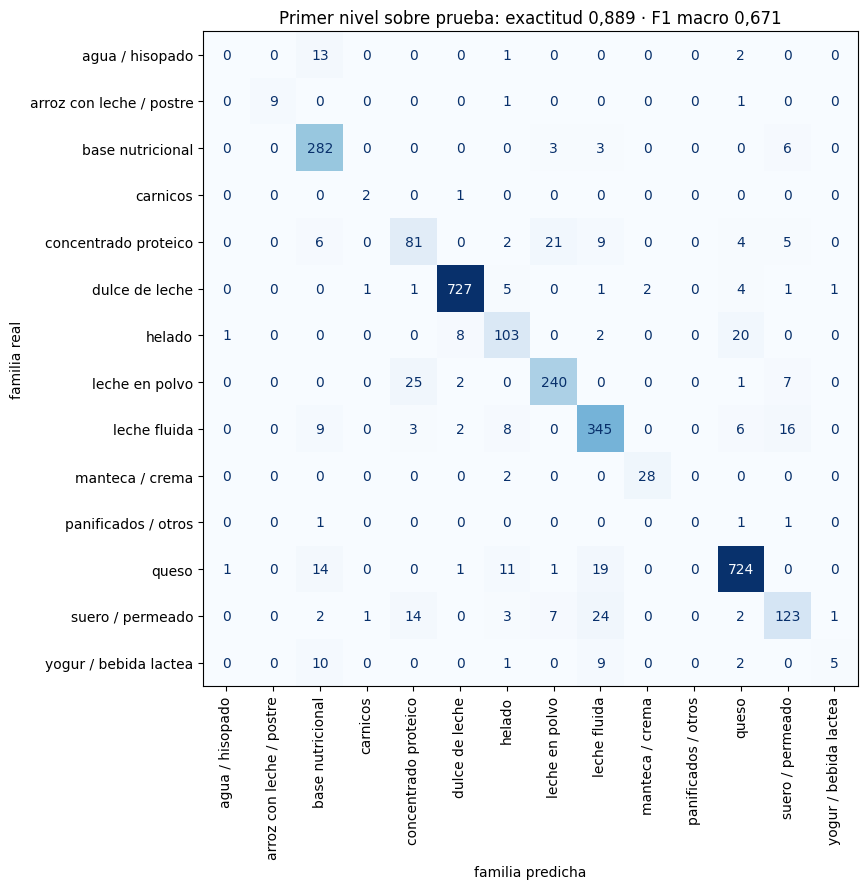

In [4]:
cf = busquedas["familia"]
arbol_familia = modelos["familia"]
pred_familia = arbol_familia.predict(pru[PREDICTORAS])
resultados_familia = AD.familia_vs_base(modelos, ent, pru)
print(f"Mejor combinación: {cf.best_params_} · F1 macro de validación {coma(cf.best_score_)}")
print(f"Árbol de familia: profundidad {arbol_familia.get_depth()} · {arbol_familia.get_n_leaves()} hojas")
display(resultados_familia.style.format(precision=3, decimal=",").set_caption(f"Primer nivel sobre las {len(pru)} muestras de prueba"))
mapa = pd.DataFrame(cf.cv_results_).pivot(index="param_min_samples_leaf", columns="param_max_depth", values="mean_test_score")
mapa.columns = [str(int(v)) if pd.notna(v) else "∞" for v in mapa.columns]
mapa.index.name, mapa.columns.name = "min_samples_leaf", "max_depth"
display(mapa.style.format(precision=3, decimal=",").background_gradient(cmap="RdYlGn", axis=None)
        .set_caption("F1 macro de validación: filas min_samples_leaf, columnas max_depth"))
rep = classification_report(pru[FAMILIA], pred_familia, zero_division=0, output_dict=True)
reporte_familia = pd.DataFrame([{"clase": k, "precisión": v["precision"], "sensibilidad": v["recall"], "F1": v["f1-score"],
                                 "soporte": int(v["support"])} for k, v in rep.items()
                                if isinstance(v, dict) and k not in ("macro avg", "weighted avg")]).set_index("clase")
display(reporte_familia.style.format(precision=3, decimal=",").format("{:.0f}", subset=["soporte"])
        .background_gradient(subset=["F1"], cmap="RdYlGn", vmin=0, vmax=1).set_caption("Reporte de clasificación de la familia (prueba)"))
fig, ax = plt.subplots(figsize=(11, 9))
ConfusionMatrixDisplay.from_predictions(pru[FAMILIA], pred_familia, cmap="Blues", xticks_rotation=90, colorbar=False, ax=ax)
ax.set_xlabel("familia predicha"); ax.set_ylabel("familia real")
ax.set_title(f"Primer nivel sobre prueba: exactitud {coma(resultados_familia.loc['árbol de familia', 'exactitud'])} · "
             f"F1 macro {coma(resultados_familia.loc['árbol de familia', 'F1 (macro)'])}")
plt.tight_layout(); plt.show()

### Cómo es el árbol de familia

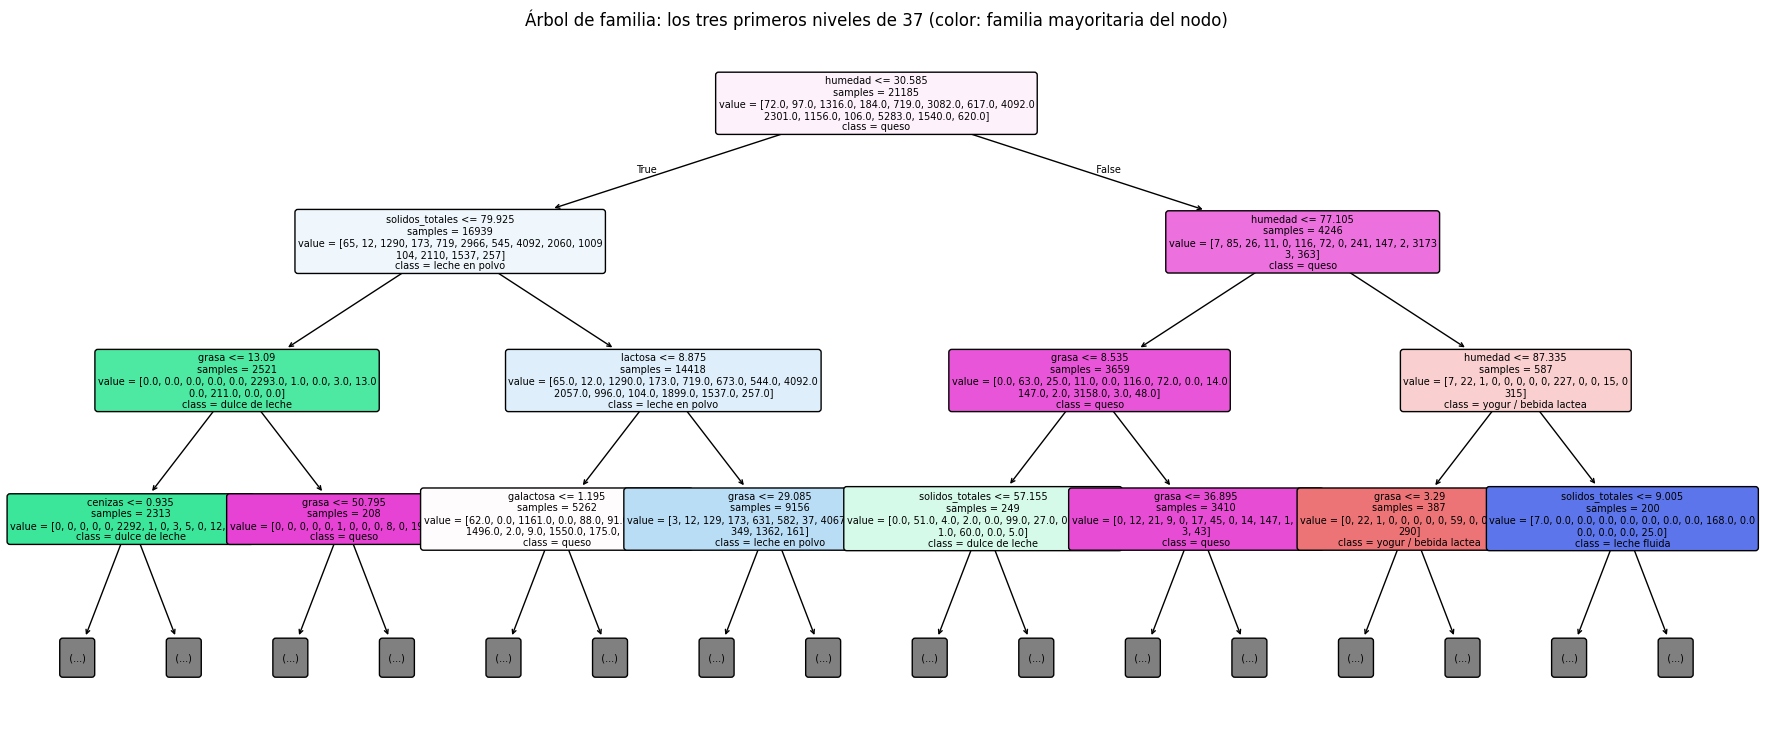

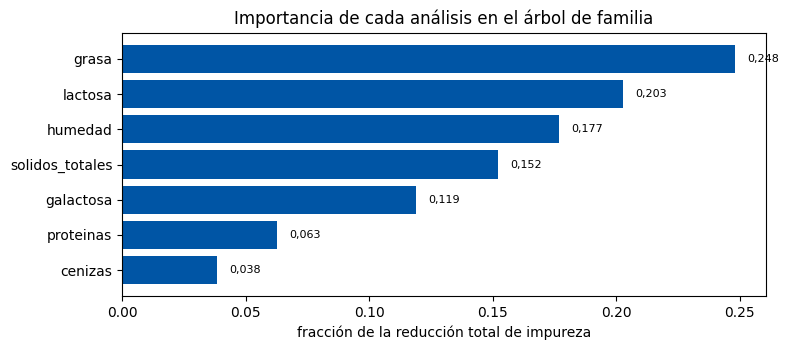

Raíz: ¿humedad ≤ 30,59? · las faltantes van a la izquierda


In [5]:
fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(arbol_familia, max_depth=3, feature_names=PREDICTORAS, class_names=list(arbol_familia.classes_), filled=True,
          rounded=True, fontsize=7, impurity=False, proportion=False, ax=ax)
ax.set_title(f"Árbol de familia: los tres primeros niveles de {arbol_familia.get_depth()} (color: familia mayoritaria del nodo)")
plt.show()
importancias = pd.Series(arbol_familia.feature_importances_, index=PREDICTORAS).sort_values()
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(importancias.index, importancias.values, color=AZUL)
for k, v in enumerate(importancias.values):
    ax.text(v + 0.005, k, coma(v), va="center", fontsize=8)
ax.set_xlabel("fracción de la reducción total de impureza"); ax.set_title("Importancia de cada análisis en el árbol de familia")
plt.tight_layout(); plt.show()
t_ = arbol_familia.tree_
print(f"Raíz: ¿{PREDICTORAS[t_.feature[0]]} ≤ {coma(t_.threshold[0], 2)}? · las faltantes van a la "
      f"{'izquierda' if t_.missing_go_to_left[0] else 'derecha'}")

### Curvas ROC de la familia

Una curva por familia (uno contra el resto) con las probabilidades del árbol, más la curva micro (todas las clases
juntas). Un árbol da pocas probabilidades distintas, por eso las curvas tienen pocos escalones.

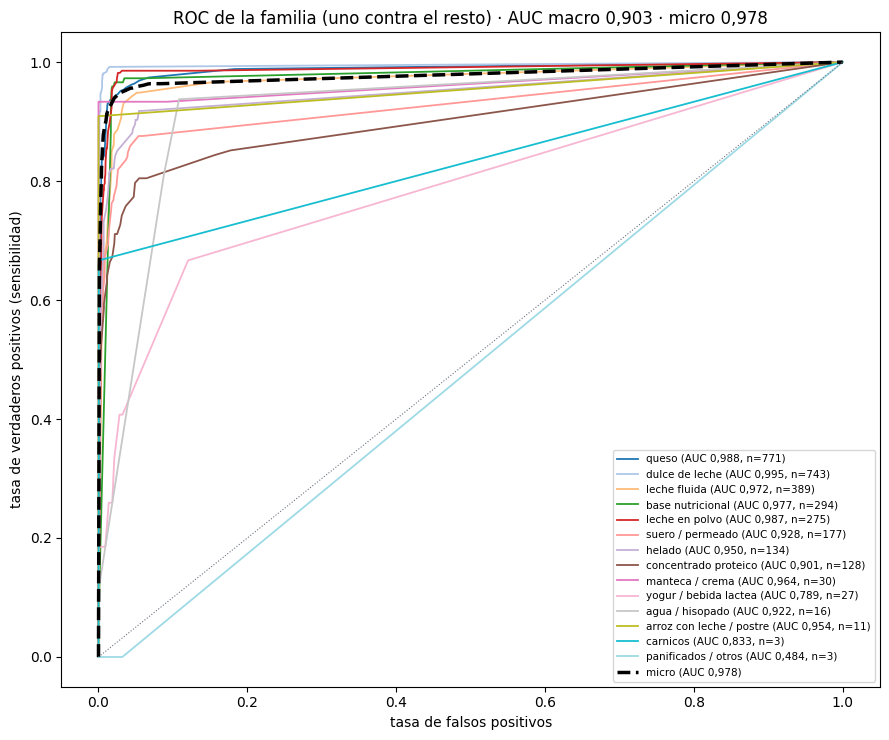

AUC familia: macro 0,903 · micro 0,978


In [6]:
roc_familia, omitidas_familia = AD.roc_ovr(pru[FAMILIA], arbol_familia.predict_proba(pru[PREDICTORAS]), arbol_familia.classes_)
fig, ax = plt.subplots(figsize=(9, 7.5))
colores = plt.cm.tab20(np.linspace(0, 1, len(roc_familia["clases"])))
for cu, col in zip(sorted(roc_familia["clases"], key=lambda x: -x["soporte"]), colores):
    ax.plot(cu["fpr"], cu["tpr"], color=col, lw=1.3, label=f"{cu['clase']} (AUC {coma(cu['auc'])}, n={cu['soporte']})")
ax.plot(roc_familia["fpr"], roc_familia["tpr"], color="black", lw=2.5, ls="--", label=f"micro (AUC {coma(roc_familia['auc_micro'])})")
ax.plot([0, 1], [0, 1], color=GRIS, lw=0.8, ls=":")
ax.set_xlabel("tasa de falsos positivos"); ax.set_ylabel("tasa de verdaderos positivos (sensibilidad)")
ax.set_title(f"ROC de la familia (uno contra el resto) · AUC macro {coma(roc_familia['auc_macro'])} · micro {coma(roc_familia['auc_micro'])}")
ax.legend(fontsize=7.5, loc="lower right"); plt.tight_layout(); plt.show()
print(f"AUC familia: macro {coma(roc_familia['auc_macro'])} · micro {coma(roc_familia['auc_micro'])}"
      + (f" · sin muestras en la prueba: {', '.join(map(str, omitidas_familia))}" if omitidas_familia else ""))

## 4. Segundo nivel: el subtipo dentro de cada familia (V3)

Cada árbol se mide sobre las muestras de prueba de su familia **real**: es la calidad del segundo nivel aislado. Esta
tabla usa la predicción cruda del árbol, sin el umbral de SIN CLASIFICAR.
- **(a)** todas las clases, SIN CLASIFICAR incluida.
- **(b)** solo las muestras con subtipo real, que es lo comparable con V1.

In [7]:
resultados_subtipo = AD.tabla_subtipo(modelos, busquedas, plan, ent, pru, "V3")
CON_ARBOL = list(resultados_subtipo.index[resultados_subtipo["tipo"] == "árbol"])
tabla_s = resultados_subtipo.copy()
tabla_s["max_depth"] = [("∞" if pd.isna(v) else f"{int(v)}") if t == "árbol" else "—" for v, t in zip(tabla_s["max_depth"], tabla_s["tipo"])]
ENTEROS = ["min_samples_leaf", "pliegues", "hojas"]
display(tabla_s.style.format({k: (lambda v: "—" if pd.isna(v) else f"{int(v)}") for k in ENTEROS})
        .format(precision=3, decimal=",", na_rep="—", subset=[k for k in tabla_s.columns if k not in ["tipo", "max_depth", *ENTEROS]])
        .background_gradient(subset=["F1 macro (a)", "F1 macro (b)"], cmap="RdYlGn", vmin=0, vmax=1)
        .set_caption("Segundo nivel por familia, con la familia real y sin umbral: (a) todas las clases; (b) solo subtipo real"))
tabla_imp = pd.DataFrame({"familia (nivel 1)": arbol_familia.feature_importances_,
                          **{f: modelos["subtipo"][f]["modelo"].feature_importances_ for f in CON_ARBOL}}, index=PREDICTORAS).T
display(tabla_imp.style.format(precision=2, decimal=",").background_gradient(cmap="Blues", axis=1, vmin=0, vmax=1)
        .set_caption("Importancia de cada análisis en cada árbol (cada fila suma 1)"))

,tipo,clases,entrenamiento,prueba (a),prueba (b),max_depth,min_samples_leaf,pliegues,F1 macro validación,hojas,exactitud (a),F1 macro (a),F1 macro base (a),exactitud (b),F1 macro (b),F1 macro base (b),% reales → SIN CLASIFICAR
familia,,,,,,,,,,,,,,,,,
agua / hisopado,árbol,4,72,16,15,3,1,5,"0,619",5,"0,562","0,508","0,180","0,533","0,456","0,250","0,067"
arroz con leche / postre,árbol,3,97,11,11,5,1,4,"0,784",8,"1,000","1,000","0,450","1,000","1,000","0,450","0,000"
base nutricional,árbol,3,1316,294,52,5,1,5,"0,513",13,"0,827","0,468","0,301","0,019","0,250","0,000","0,981"
concentrado proteico,árbol,6,719,128,119,∞,1,5,"0,671",59,"0,953","0,834","0,146","0,966","0,886","0,183","0,017"
dulce de leche,árbol,4,3082,743,561,8,1,5,"0,731",128,"0,708","0,719","0,128","0,774","0,814","0,209","0,082"
leche en polvo,árbol,3,4092,275,21,6,1,5,"0,606",21,"0,945","0,839","0,320","0,476","0,810","0,000","0,524"
leche fluida,árbol,6,2301,389,297,∞,1,5,"0,621",558,"0,699","0,495","0,130","0,791","0,584","0,182","0,162"
manteca / crema,árbol,4,1156,30,30,5,10,3,"0,539",9,"0,933","0,327","0,000","0,933","0,327","0,000","0,000"
queso,árbol,31,5283,771,540,∞,5,5,"0,294",636,"0,521","0,248","0,015","0,465","0,251","0,000","0,222"


,humedad,grasa,proteinas,cenizas,solidos_totales,lactosa,galactosa
familia (nivel 1),"0,18","0,25","0,06","0,04","0,15","0,20","0,12"
agua / hisopado,"0,00","0,00","0,00","0,00","0,00","0,81","0,19"
arroz con leche / postre,"0,21","0,25","0,48","0,00","0,00","0,00","0,07"
base nutricional,"0,00","0,05","0,00","0,13","0,05","0,76","0,02"
concentrado proteico,"0,05","0,17","0,19","0,15","0,01","0,37","0,06"
dulce de leche,"0,05","0,12","0,16","0,25","0,37","0,03","0,01"
leche en polvo,"0,00","0,15","0,43","0,01","0,00","0,38","0,02"
leche fluida,"0,06","0,11","0,16","0,03","0,02","0,24","0,38"
manteca / crema,"0,00","0,85","0,03","0,00","0,12","0,00","0,00"
queso,"0,32","0,29","0,08","0,00","0,13","0,05","0,13"


### ROC, matrices y reportes del subtipo

Son las muestras de prueba de cada familia real que tienen subtipo agrupado, sea un subtipo real o SIN CLASIFICAR.
- La ROC usa las probabilidades del árbol tal como salen.
- Las matrices y los reportes usan la predicción **con el umbral de 0,85**.

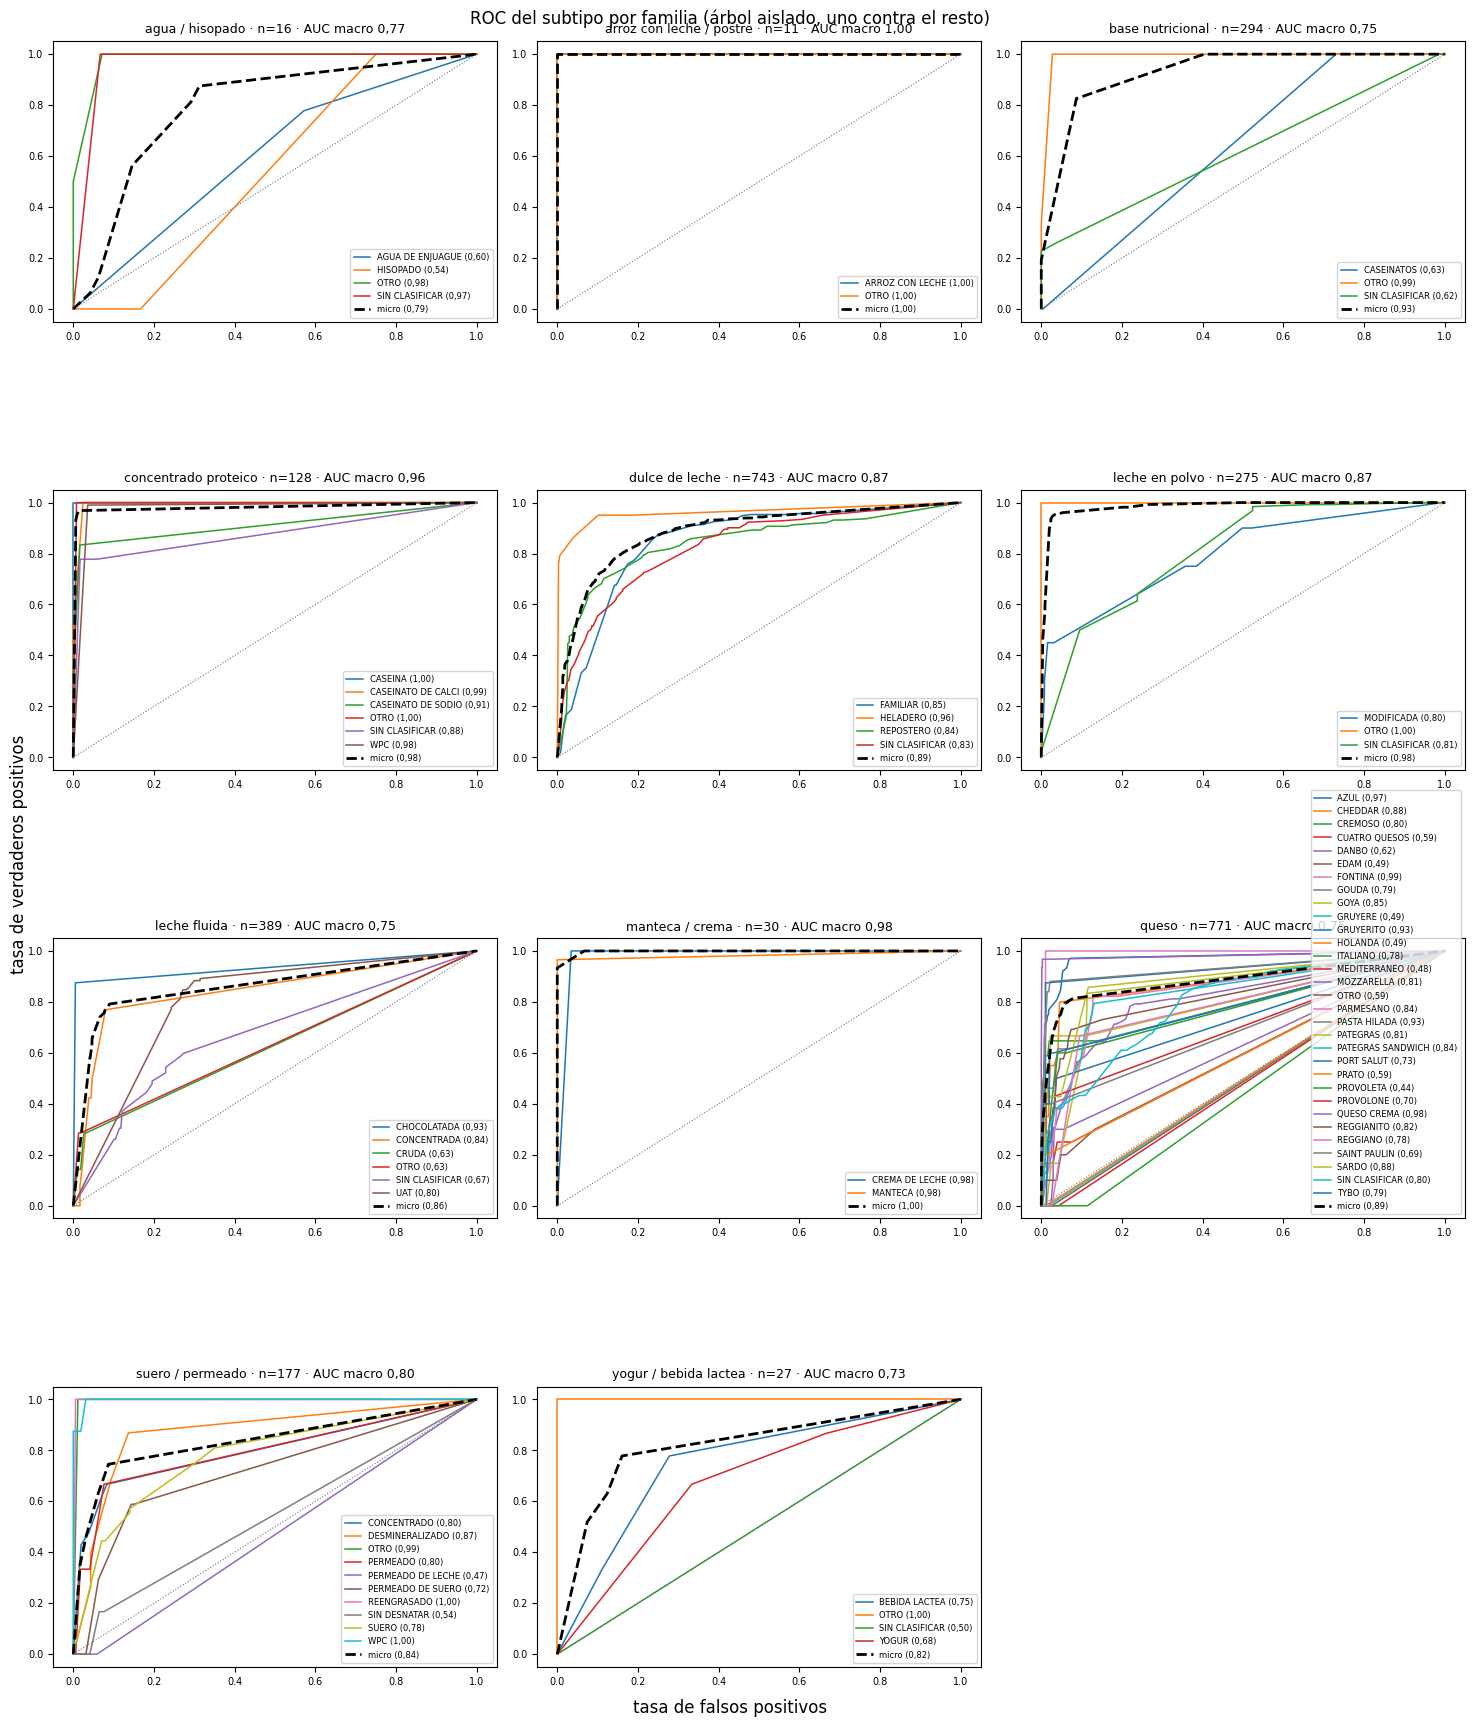

,muestras,AUC macro,AUC micro
agua / hisopado,16,"0,773","0,794"
arroz con leche / postre,11,"1,000","1,000"
base nutricional,294,"0,748","0,930"
concentrado proteico,128,"0,959","0,981"
dulce de leche,743,"0,872","0,886"
leche en polvo,275,"0,868","0,984"
leche fluida,389,"0,753","0,862"
manteca / crema,30,"0,983","0,998"
queso,771,"0,748","0,888"
suero / permeado,177,"0,798","0,839"


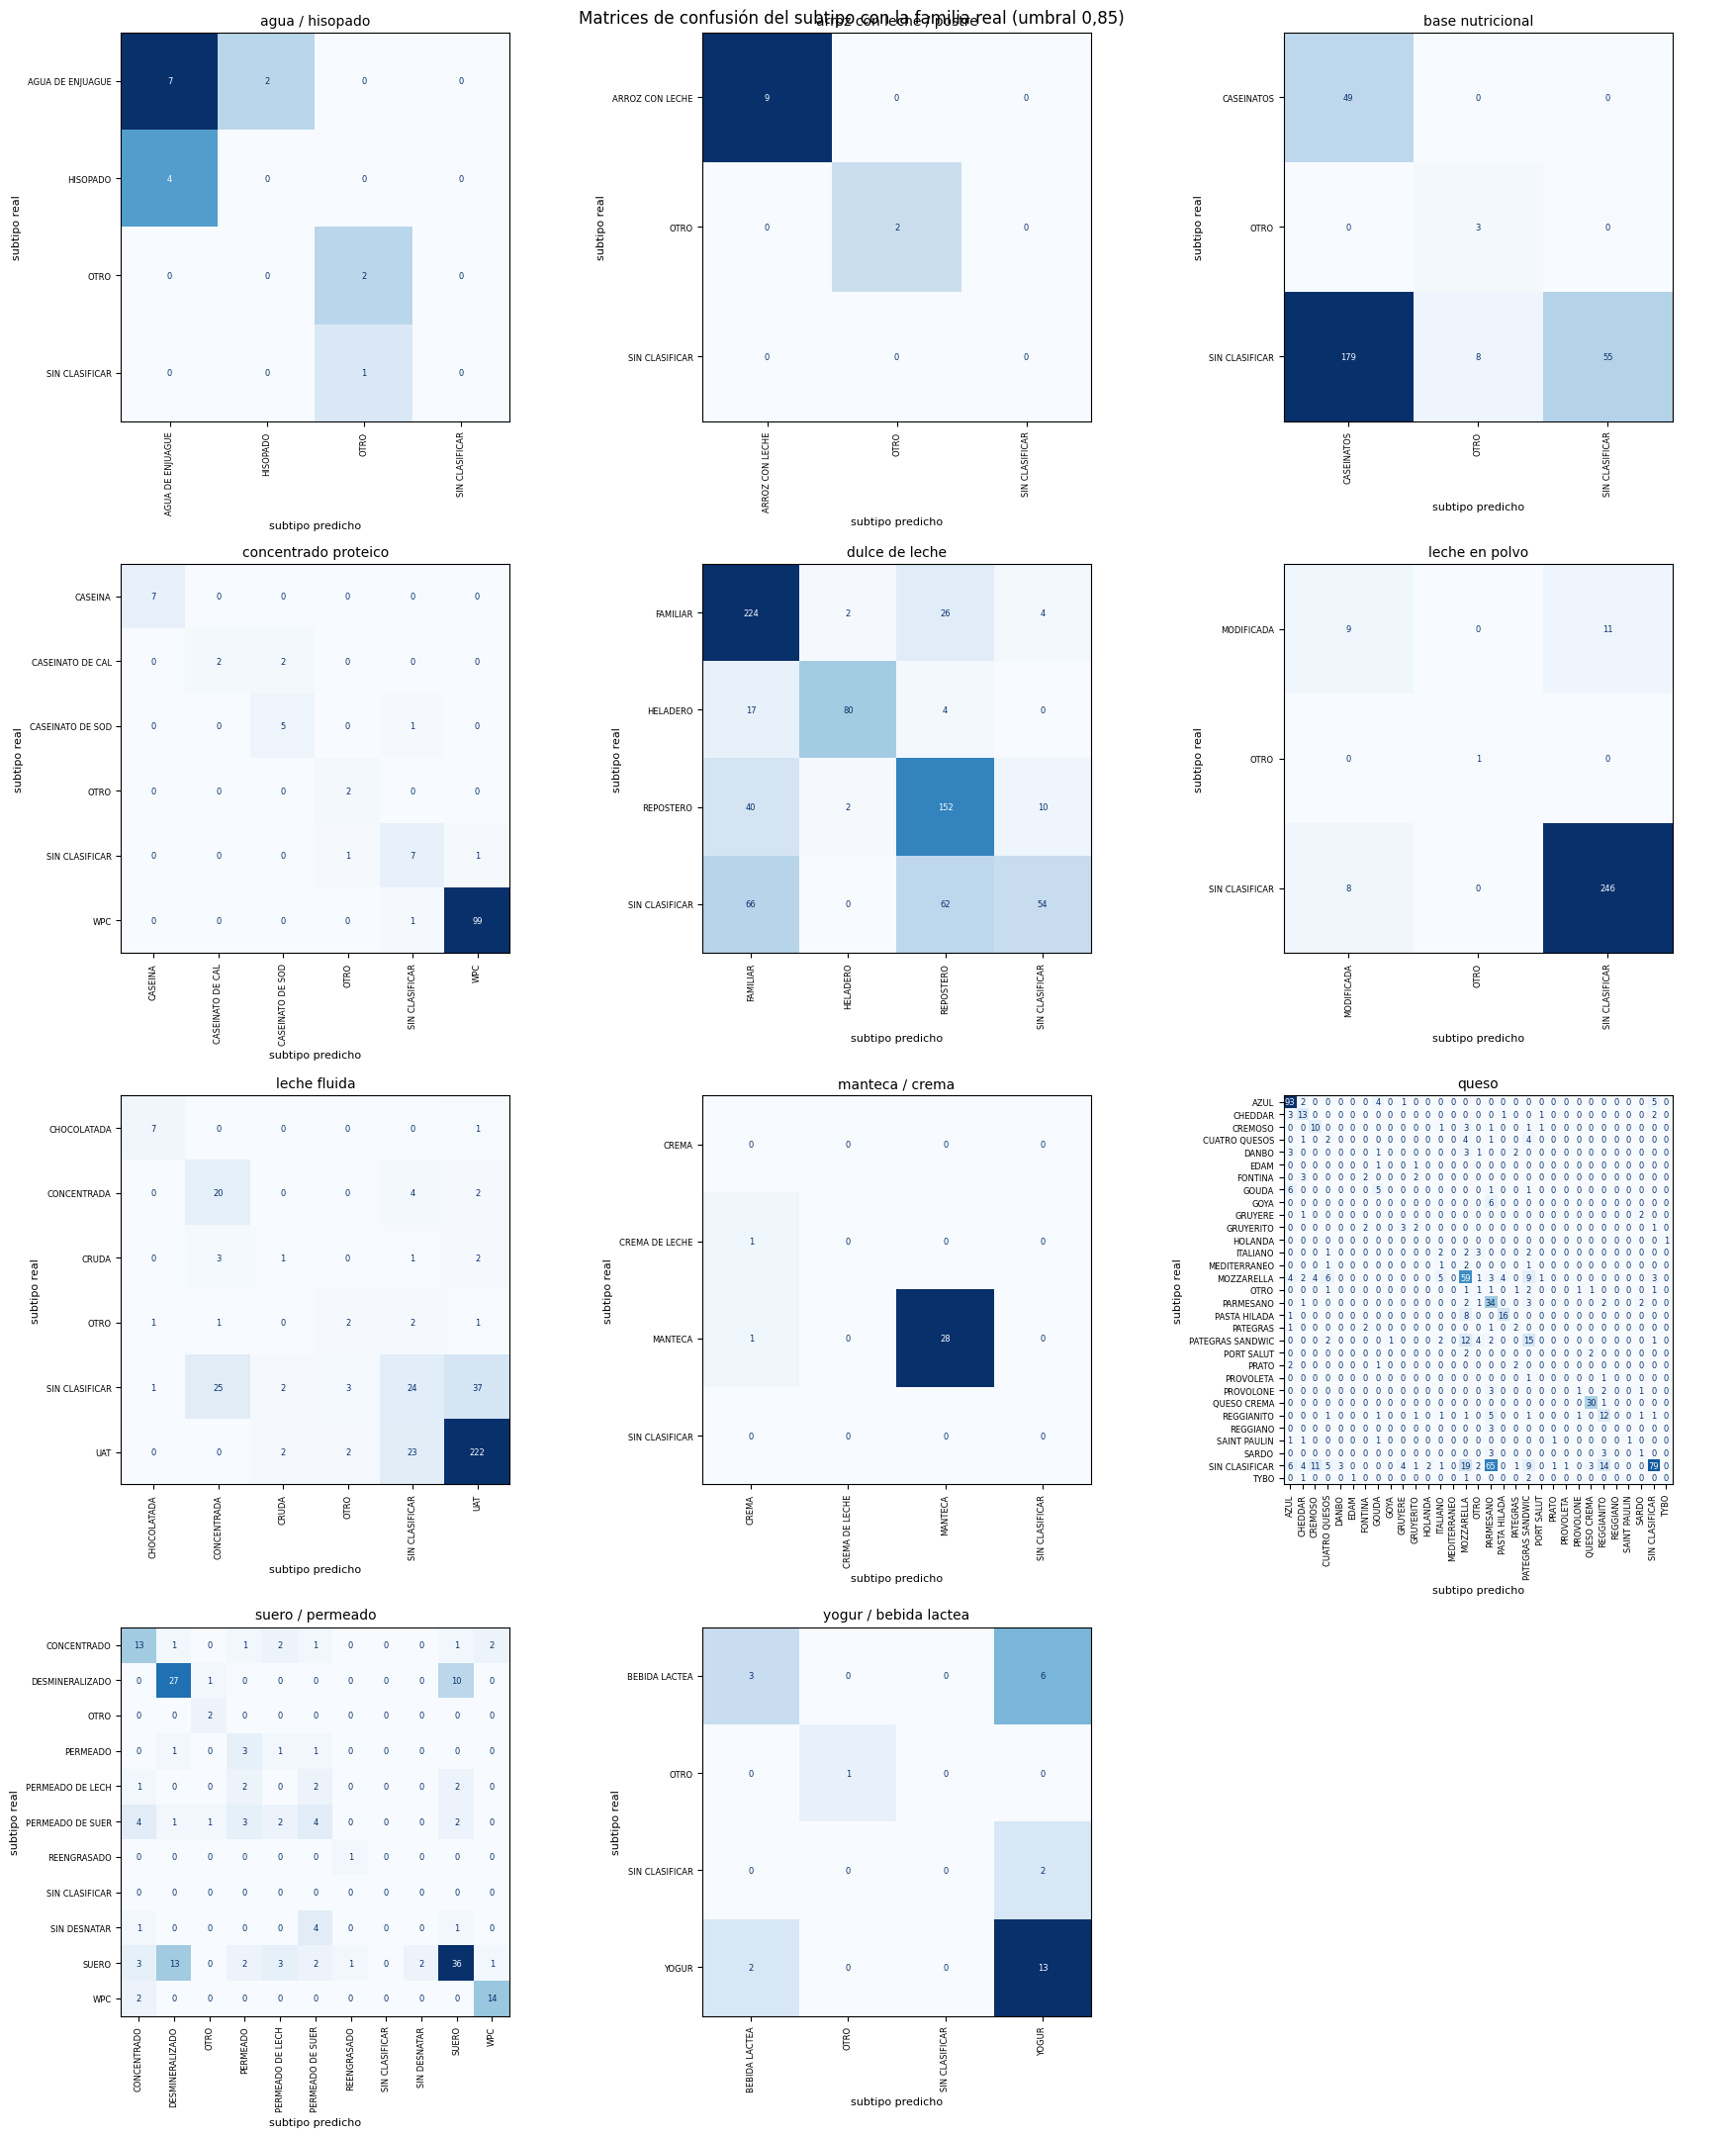

,precisión,sensibilidad,F1,soporte
clase,,,,
AZUL,"0,775","0,886","0,827",105
CHEDDAR,"0,448","0,650","0,531",20
CREMOSO,"0,400","0,588","0,476",17
CUATRO QUESOS,"0,105","0,167","0,129",12
DANBO,"0,000","0,000","0,000",10
EDAM,"0,000","0,000","0,000",2
FONTINA,"0,333","0,286","0,308",7
GOUDA,"0,357","0,385","0,370",13
GOYA,"0,000","0,000","0,000",6


,precisión,sensibilidad,F1,soporte
clase,,,,
FAMILIAR,"0,646","0,875","0,743",256
HELADERO,"0,952","0,792","0,865",101
REPOSTERO,"0,623","0,745","0,679",204
SIN CLASIFICAR,"0,794","0,297","0,432",182


,precisión,sensibilidad,F1,soporte
clase,,,,
CHOCOLATADA,"0,778","0,875","0,824",8
CONCENTRADA,"0,408","0,769","0,533",26
CRUDA,"0,200","0,143","0,167",7
OTRO,"0,286","0,286","0,286",7
SIN CLASIFICAR,"0,444","0,261","0,329",92
UAT,"0,838","0,892","0,864",249


,precisión,sensibilidad,F1,soporte
clase,,,,
CASEINATOS,"0,215","1,000","0,354",49
OTRO,"0,273","1,000","0,429",3
SIN CLASIFICAR,"1,000","0,227","0,370",242


In [8]:
roc_subtipo, conf_subtipo, reportes_subtipo, sin_prueba = {}, {}, {}, []
n_ = len(CON_ARBOL); columnas = 3; filas_g = int(np.ceil(n_ / columnas))
fig, ejes = plt.subplots(filas_g, columnas, figsize=(5 * columnas, 4.4 * filas_g), squeeze=False)
for ax, familia in zip(ejes.ravel(), CON_ARBOL):
    arbol = modelos["subtipo"][familia]["modelo"]
    en_pru = (pru[FAMILIA] == familia) & pru[AGRUPADO].notna()
    Xf, yf = pru.loc[en_pru, PREDICTORAS], pru.loc[en_pru, AGRUPADO]
    r, omit = AD.roc_ovr(yf, arbol.predict_proba(Xf), arbol.classes_) if len(yf) else (None, [])
    if r is None:
        sin_prueba.append(familia); ax.axis("off"); continue
    roc_subtipo[familia] = r
    for cu in r["clases"]:
        ax.plot(cu["fpr"], cu["tpr"], lw=1.1, label=f"{cu['clase'][:18]} ({coma(cu['auc'], 2)})")
    ax.plot(r["fpr"], r["tpr"], color="black", lw=2, ls="--", label=f"micro ({coma(r['auc_micro'], 2)})")
    ax.plot([0, 1], [0, 1], color=GRIS, lw=0.8, ls=":")
    ax.set_title(f"{familia} · n={len(yf)} · AUC macro {coma(r['auc_macro'], 2)}", fontsize=9)
    ax.legend(fontsize=6, loc="lower right"); ax.tick_params(labelsize=7)
    pred_u, _ = AD.predecir_subtipo(modelos["subtipo"][familia], Xf, AD.UMBRAL_SIN_CLASIFICAR)
    etiquetas = list(arbol.classes_)
    conf_subtipo[familia] = (etiquetas, confusion_matrix(yf, pred_u, labels=etiquetas))
    rep = classification_report(yf, pred_u, labels=etiquetas, zero_division=0, output_dict=True)
    reportes_subtipo[familia] = pd.DataFrame([{"clase": k, "precisión": rep[k]["precision"], "sensibilidad": rep[k]["recall"],
                                               "F1": rep[k]["f1-score"], "soporte": int(rep[k]["support"])} for k in etiquetas]).set_index("clase")
for ax in ejes.ravel()[n_:]:
    ax.axis("off")
fig.supxlabel("tasa de falsos positivos"); fig.supylabel("tasa de verdaderos positivos")
fig.suptitle("ROC del subtipo por familia (árbol aislado, uno contra el resto)", fontsize=12)
plt.tight_layout(); plt.show()
display(pd.DataFrame({f: {"muestras": sum(cu["soporte"] for cu in r["clases"]), "AUC macro": r["auc_macro"], "AUC micro": r["auc_micro"]}
                      for f, r in roc_subtipo.items()}).T
        .style.format(precision=3, decimal=",", subset=["AUC macro", "AUC micro"]).format("{:.0f}", subset=["muestras"])
        .set_caption("AUC del subtipo por familia"))
CON_PRUEBA = list(conf_subtipo)
fig, ejes = plt.subplots(int(np.ceil(len(CON_PRUEBA) / columnas)), columnas, figsize=(6 * columnas, 5.5 * int(np.ceil(len(CON_PRUEBA) / columnas))), squeeze=False)
for ax, familia in zip(ejes.ravel(), CON_PRUEBA):
    etiquetas, matriz = conf_subtipo[familia]
    ConfusionMatrixDisplay(matriz, display_labels=[e[:16] for e in etiquetas]).plot(cmap="Blues", xticks_rotation=90, colorbar=False, ax=ax)
    ax.set_title(familia, fontsize=10); ax.set_xlabel("subtipo predicho", fontsize=8); ax.set_ylabel("subtipo real", fontsize=8)
    ax.tick_params(labelsize=6)
    for t in ax.texts:
        t.set_fontsize(6)
for ax in ejes.ravel()[len(CON_PRUEBA):]:
    ax.axis("off")
fig.suptitle(f"Matrices de confusión del subtipo con la familia real (umbral {coma(AD.UMBRAL_SIN_CLASIFICAR, 2)})", fontsize=12)
plt.tight_layout(); plt.show()
for familia in resultados_subtipo.loc[CON_PRUEBA, "prueba (a)"].sort_values(ascending=False).index[:4]:
    display(reportes_subtipo[familia].style.format(precision=3, decimal=",").format("{:.0f}", subset=["soporte"])
            .background_gradient(subset=["F1"], cmap="RdYlGn", vmin=0, vmax=1).set_caption(f"Reporte del subtipo · {familia}"))
if sin_prueba:
    print("Familias con árbol pero sin ROC (sin muestras de prueba o con una sola clase):", ", ".join(sin_prueba))

## 5. La cascada de punta a punta (V3, umbral 0,85)

Primero se predice la familia y después el subtipo, con el modelo de esa familia. Si el primer árbol se equivoca, el
subtipo va a un árbol que no corresponde. Cuenta como acierto solo si familia y subtipo son correctos.

«Con familia real» es la cascada ideal, en la que el segundo nivel recibe la familia correcta. Las familias sin subtipos
quedan afuera.

In [9]:
T = {v: AD.muestra_a_muestra(E[v][0], D[v].pru) for v in AD.VERSIONES}     # una fila por muestra de prueba (Identificador)
t3 = T["V3"]
ev3 = pd.Series(AD.evaluar(modelos, pru))
ev3_crudo = pd.Series(AD.evaluar(modelos, pru, crudo=True))
familia_comun = ent[FAMILIA].mode()[0]
subtipo_comun = ent.loc[ent[FAMILIA] == familia_comun, AGRUPADO].mode()[0]
base = ((pru[FAMILIA] == familia_comun) & (pru[AGRUPADO] == subtipo_comun))
con_sub, con_real = pru[AGRUPADO].notna(), pru[SUBTIPO].notna()
resumen_cascada = pd.DataFrame({
    "(a) todas las clases": {"muestras de prueba": con_sub.sum(), "familia correcta": t3["acierto familia"].to_numpy()[con_sub.to_numpy()].mean(),
                             "familia y subtipo (punta a punta)": ev3["punta a punta (a)"], "subtipo con familia real": ev3["con familia real (a)"],
                             f"línea de base ({familia_comun} → {subtipo_comun})": base[con_sub].mean()},
    "(b) solo subtipo real": {"muestras de prueba": con_real.sum(), "familia correcta": t3["acierto familia"].to_numpy()[con_real.to_numpy()].mean(),
                              "familia y subtipo (punta a punta)": ev3["punta a punta (b)"], "subtipo con familia real": ev3["con familia real (b)"],
                              f"línea de base ({familia_comun} → {subtipo_comun})": base[con_real].mean()}})
display(resumen_cascada.style.format(precision=3, decimal=",").format("{:.0f}", subset=pd.IndexSlice["muestras de prueba", :])
        .set_caption("De punta a punta sobre la prueba, en las dos versiones"))
for v in ["(a)", "(b)"]:
    print(f"{v}: familia y subtipo correctos {coma(ev3[f'punta a punta {v}'] * 100, 1)} % · con la familia real "
          f"{coma(ev3[f'con familia real {v}'] * 100, 1)} % · se pierden "
          f"{coma((ev3[f'con familia real {v}'] - ev3[f'punta a punta {v}']) * 100, 1)} puntos por errores del primer nivel")
print(f"De las {con_real.sum()} muestras de prueba con subtipo real, la cascada da {SC} a {coma(ev3['reales → SIN CLASIFICAR'] * 100, 1)} % "
      f"con el umbral de {coma(AD.UMBRAL_SIN_CLASIFICAR, 2)}; sin umbral serían {coma(ev3_crudo['reales → SIN CLASIFICAR'] * 100, 1)} %")
g = t3["familia real"].to_numpy()
m_a, m_b = con_sub.to_numpy(), con_real.to_numpy()
por_familia = pd.DataFrame({"muestras (a)": pd.Series(m_a).groupby(g).sum(), "muestras (b)": pd.Series(m_b).groupby(g).sum(),
                            "familia correcta (b)": t3["acierto familia"][m_b].groupby(g[m_b]).mean(),
                            "familia y subtipo (a)": t3["acierto subtipo"][m_a].groupby(g[m_a]).mean(),
                            "familia y subtipo (b)": t3["acierto subtipo"][m_b].groupby(g[m_b]).mean(),
                            f"reales → {SC}": (t3["subtipo predicho"] == SC)[m_b].groupby(g[m_b]).mean()})
por_familia = por_familia[por_familia["muestras (a)"] > 0]
display(por_familia.style.format(precision=3, decimal=",", na_rep="—").format("{:.0f}", subset=["muestras (a)", "muestras (b)"])
        .background_gradient(subset=["familia y subtipo (a)", "familia y subtipo (b)"], cmap="RdYlGn", vmin=0, vmax=1)
        .set_caption("De punta a punta, por familia real: (a) todas las clases; (b) solo subtipo real"))

,(a) todas las clases,(b) solo subtipo real
muestras de prueba,2861,1848
familia correcta,"0,896","0,880"
familia y subtipo (punta a punta),"0,568","0,651"
subtipo con familia real,"0,635","0,731"
línea de base (queso → SIN CLASIFICAR),"0,081","0,000"


(a): familia y subtipo correctos 56,8 % · con la familia real 63,5 % · se pierden 6,7 puntos por errores del primer nivel
(b): familia y subtipo correctos 65,1 % · con la familia real 73,1 % · se pierden 8,0 puntos por errores del primer nivel
De las 1848 muestras de prueba con subtipo real, la cascada da SIN CLASIFICAR a 5,6 % con el umbral de 0,85; sin umbral serían 19,4 %


,muestras (a),muestras (b),familia correcta (b),familia y subtipo (a),familia y subtipo (b),reales → SIN CLASIFICAR
agua / hisopado,16,15,"0,000","0,000","0,000","0,133"
arroz con leche / postre,11,11,"0,818","0,818","0,818","0,000"
base nutricional,294,52,"0,942","0,354","0,942","0,000"
concentrado proteico,128,119,"0,630","0,625","0,630","0,176"
dulce de leche,743,561,"0,979","0,678","0,804","0,029"
leche en polvo,275,21,"0,762","0,825","0,286","0,476"
leche fluida,389,297,"0,912","0,656","0,808","0,084"
manteca / crema,30,30,"0,933","0,933","0,933","0,000"
queso,771,540,"0,933","0,445","0,500","0,028"
suero / permeado,177,177,"0,695","0,407","0,407","0,068"


## 6. Errores más frecuentes (V3)

Los 15 pares real → predicho más repetidos en cada nivel.
- En la familia, sobre toda la prueba.
- En el subtipo, entre las muestras cuya familia la cascada acertó, con el umbral de 0,85.

El original mostraba descripciones de ejemplo; acá no se muestran.

In [10]:
errores_familia, errores_subtipo = AD.errores_frecuentes(t3)
display(errores_familia.style.hide(axis="index").set_caption("Los errores más frecuentes de la familia"))
display(errores_subtipo.style.hide(axis="index").set_caption("Los errores más frecuentes del subtipo (familia bien predicha)"))

familia real,familia predicha,muestras
leche en polvo,concentrado proteico,25
suero / permeado,leche fluida,24
concentrado proteico,leche en polvo,21
helado,queso,20
queso,leche fluida,19
leche fluida,suero / permeado,16
queso,base nutricional,14
suero / permeado,concentrado proteico,14
agua / hisopado,base nutricional,13
queso,helado,11


familia real,subtipo real,subtipo predicho,muestras
base nutricional,SIN CLASIFICAR,CASEINATOS,178
queso,SIN CLASIFICAR,PARMESANO,65
dulce de leche,SIN CLASIFICAR,FAMILIAR,64
dulce de leche,SIN CLASIFICAR,REPOSTERO,61
dulce de leche,REPOSTERO,FAMILIAR,38
leche fluida,SIN CLASIFICAR,UAT,33
dulce de leche,FAMILIAR,REPOSTERO,26
leche fluida,SIN CLASIFICAR,CONCENTRADA,24
leche fluida,UAT,SIN CLASIFICAR,21
queso,SIN CLASIFICAR,MOZZARELLA,19


## 7. Qué aporta MQ y qué aporta el umbral

Viene de la sección C.2 de `Algoritmos.ipynb`. Son dos cascadas medidas sobre la misma prueba, el 20 % de arc de V3:
- la de **solo arc**, entrenada con el 80 % de arc y la receta de V3;
- la de **arc + MQ**, que es la de V3.

Cada una se mide sin umbral, con 0,7 (solo como prueba) y con 0,85, el umbral que se guarda. Las dos usan las mismas
clases. En la tabla, el F1 de subtipo de cada familia se calcula con la familia real.

In [11]:
t0 = time.time()
modelos_solo_arc, _, _ = AD.entrenar_cascada(D3.ent_arc, D3.familias, "V3", umbral=AD.UMBRAL_SIN_CLASIFICAR)
UMBRALES = [None, 0.7, AD.UMBRAL_SIN_CLASIFICAR]
comparacion = pd.DataFrame({f"{nombre} · {'sin umbral' if u is None else 'umbral ' + coma(u, 2).rstrip('0')}":
                            AD.evaluar(m, pru, crudo=u is None, umbral=u, por_familia=True)
                            for nombre, m in [("solo arc", modelos_solo_arc), ("arc + MQ", modelos)] for u in UMBRALES})
print(f"Entrenamiento: solo arc {len(D3.ent_arc)} · arc + MQ {len(ent)} · prueba, la misma para todas: {len(pru)} de arc "
      f"({coma(time.time() - t0, 0)} s)")
display(comparacion.style.format(precision=3, decimal=",", na_rep="—").background_gradient(cmap="RdYlGn", axis=1)
        .set_caption(f"Las dos cascadas con tres umbrales, sobre las {len(pru)} muestras de prueba de arc"))

Entrenamiento: solo arc 12001 · arc + MQ 21185 · prueba, la misma para todas: 3001 de arc (5 s)


,solo arc · sin umbral,"solo arc · umbral 0,7","solo arc · umbral 0,85",arc + MQ · sin umbral,"arc + MQ · umbral 0,7","arc + MQ · umbral 0,85"
familia: exactitud,"0,898","0,898","0,898","0,889","0,889","0,889"
familia: F1 macro,"0,704","0,704","0,704","0,671","0,671","0,671"
punta a punta (a),"0,631","0,630","0,582","0,625","0,618","0,568"
con familia real (a),"0,700","0,699","0,648","0,696","0,688","0,635"
punta a punta (b),"0,564","0,617","0,655","0,577","0,614","0,651"
con familia real (b),"0,650","0,705","0,744","0,655","0,692","0,731"
reales → SIN CLASIFICAR,"0,215","0,128","0,061","0,194","0,122","0,056"
reales → SIN CLASIFICAR (familia real),"0,167","0,081","0,036","0,151","0,082","0,038"
F1 subtipo (a) · agua / hisopado,"0,508","0,508","0,375","0,508","0,508","0,375"
F1 subtipo (b) · agua / hisopado,"0,456","0,456","0,567","0,456","0,456","0,567"


## 8. Las tres versiones, una al lado de la otra

Viene de `Arbol_comparacion.ipynb`. Las columnas «original» son los números de los cuadernos del compañero, que usaban
la semilla 2026: las de familia son las de la diapositiva 6 de la presentación. Las tres pruebas no son idénticas,
porque V3 filtra más; diferencias de 1 o 2 puntos no son concluyentes.

,V1,V1 original,V2,V2 original,V3,V3 original
familia: exactitud,"0,893","0,885","0,892","0,889","0,889","0,896"
familia: F1 macro,"0,701","0,697","0,689","0,693","0,671",—
punta a punta (a),—,—,"0,631","0,639","0,568","0,561"
con familia real (a),—,—,"0,703","0,716","0,635",—
punta a punta (b),"0,666","0,676","0,587","0,589","0,651","0,621"
con familia real (b),"0,758","0,765","0,670","0,669","0,731",—
reales → SIN CLASIFICAR,—,—,"0,183","0,189","0,056","0,097"
familia: AUC macro,"0,920",—,"0,920",—,"0,903",—
familia: AUC micro,"0,983",—,"0,985",—,"0,978",—
muestras de prueba,3025,—,3025,—,3001,—


V1: exactitud de familia 89,3 % (original 88,5 %)
V2: exactitud de familia 89,2 % (original 88,9 %)
V3: exactitud de familia 88,9 % (original 89,6 %)


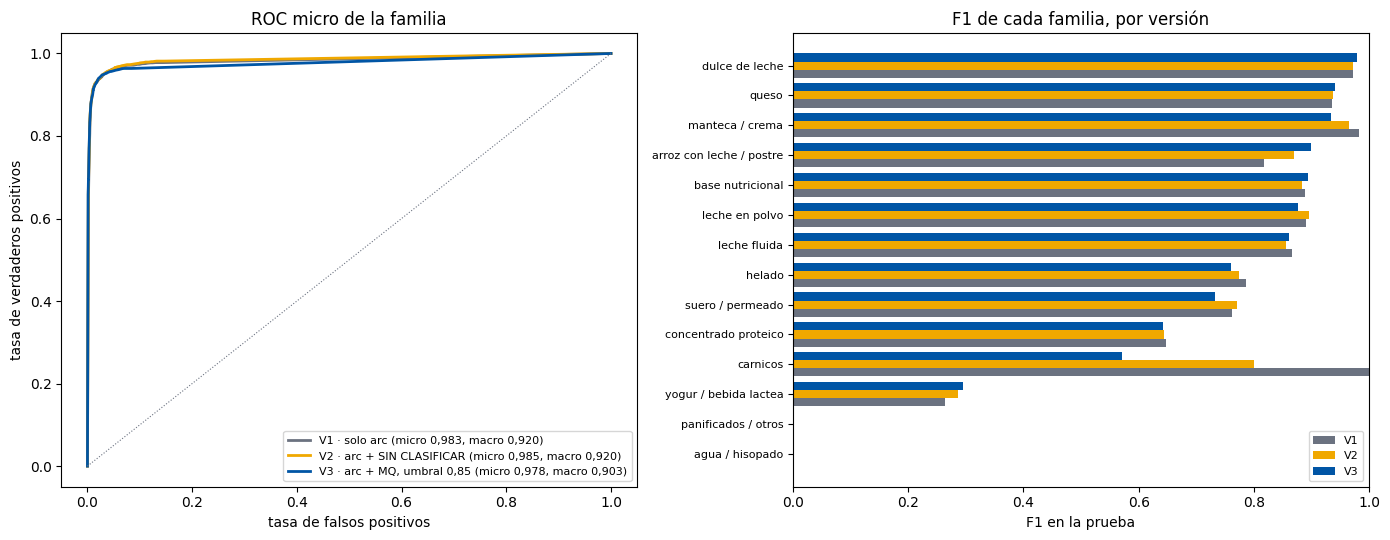

In [12]:
EV = {v: AD.evaluar(E[v][0], D[v].pru) for v in AD.VERSIONES}
ROC = {v: AD.roc_ovr(D[v].pru[FAMILIA], E[v][0]["familia"].predict_proba(D[v].pru[PREDICTORAS]), E[v][0]["familia"].classes_)[0]
       for v in AD.VERSIONES}
filas_v = {}
for v in AD.VERSIONES:
    filas_v[v] = {**EV[v], "familia: AUC macro": ROC[v]["auc_macro"], "familia: AUC micro": ROC[v]["auc_micro"],
                  "muestras de prueba": len(D[v].pru)}
    filas_v[f"{v} original"] = {k: AD.ORIGINAL[v].get(k, np.nan) for k in filas_v[v]}
versiones = pd.DataFrame(filas_v).drop(index="reales → SIN CLASIFICAR (familia real)")
display(versiones.style.format(precision=3, decimal=",", na_rep="—").format("{:.0f}", subset=pd.IndexSlice["muestras de prueba", :], na_rep="—")
        .set_caption("Métricas principales de las tres versiones (sobre su propia prueba) y las del original"))
for v in AD.VERSIONES:
    print(f"{v}: exactitud de familia {coma(EV[v]['familia: exactitud'] * 100, 1)} % (original {coma(AD.ORIGINAL[v]['familia: exactitud'] * 100, 1)} %)")

fig, ejes = plt.subplots(1, 2, figsize=(14, 5.5))
for v in AD.VERSIONES:
    ejes[0].plot(ROC[v]["fpr"], ROC[v]["tpr"], color=COLORES[v], lw=2, label=f"{AD.TITULOS[v]} (micro {coma(ROC[v]['auc_micro'])}, macro {coma(ROC[v]['auc_macro'])})")
ejes[0].plot([0, 1], [0, 1], color=GRIS, lw=0.8, ls=":")
ejes[0].set(xlabel="tasa de falsos positivos", ylabel="tasa de verdaderos positivos", title="ROC micro de la familia")
ejes[0].legend(fontsize=8, loc="lower right")
f1_fam = pd.DataFrame({v: pd.Series({r_: d_["f1-score"] for r_, d_ in classification_report(
    D[v].pru[FAMILIA], E[v][0]["familia"].predict(D[v].pru[PREDICTORAS]), zero_division=0, output_dict=True).items()
    if isinstance(d_, dict) and r_ not in ("macro avg", "weighted avg")}) for v in AD.VERSIONES})
f1_fam = f1_fam.sort_values("V3")
y_ = np.arange(len(f1_fam))
for k, v in enumerate(AD.VERSIONES):
    ejes[1].barh(y_ + (k - 1) * 0.27, f1_fam[v], 0.27, color=COLORES[v], label=v)
ejes[1].set_yticks(y_, f1_fam.index, fontsize=8); ejes[1].set_xlim(0, 1)
ejes[1].set(xlabel="F1 en la prueba", title="F1 de cada familia, por versión"); ejes[1].legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

### Las mismas muestras en las tres versiones

Para comparar muestra por muestra se toman los Identificadores que están en **las tres** pruebas. Están cargadas
hacia las familias grandes, así que sirven para ver **qué cambió**, no para reemplazar las métricas de arriba.
- En el subtipo solo entran las que tienen subtipo real en las tres, es decir, el universo de (b).
- «acierto → SIN CLASIFICAR» cuenta las que la versión nueva dejó sin subtipo.

Muestras de prueba compartidas por las tres versiones: 1456 · con subtipo real en las tres: 745


,V1,V2,V3
familia,"0,920","0,920","0,906"
familia y subtipo (b),"0,718","0,626","0,734"


,V1 → V2,V2 → V3,V1 → V3
acierto → acierto,1335,1302,1302
acierto → error,5,38,38
error → acierto,5,17,17
error → error,111,99,99


,V1 → V2,V2 → V3,V1 → V3
acierto → acierto,441,440,500
acierto → error,94,26,35
error → acierto,25,107,47
error → error,185,172,163
"de esas, acierto → SIN CLASIFICAR",70,8,13


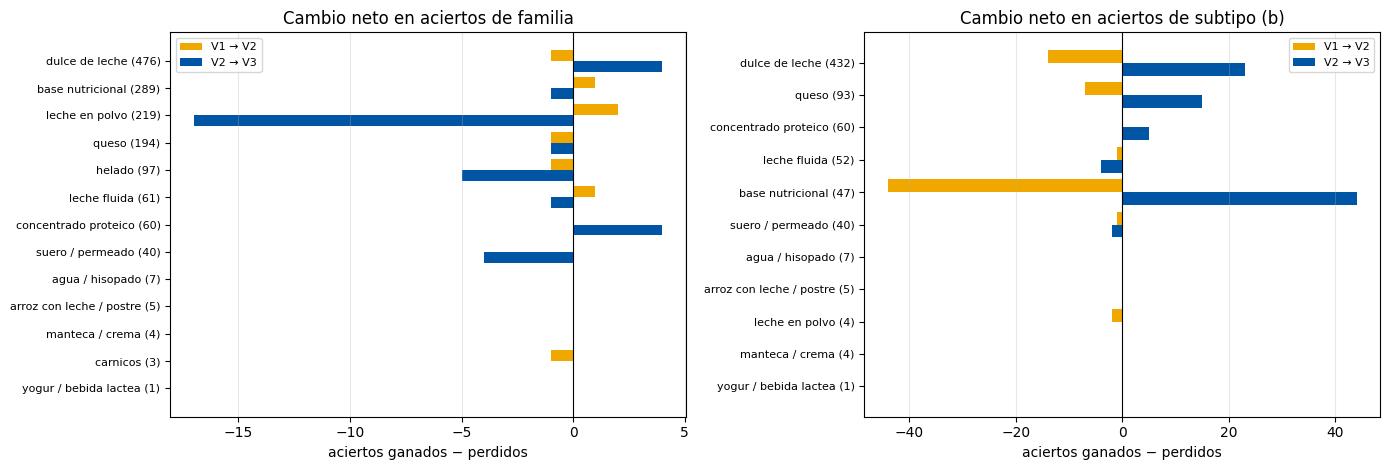

In [13]:
comp = AD.compartidas(T)
print(f"Muestras de prueba compartidas por las tres versiones: {comp.n} · con subtipo real en las tres: {comp.n_b}")
display(comp.exactitud.style.format(precision=3, decimal=",").set_caption("Exactitud sobre las mismas muestras"))
display(comp.familia.style.set_caption("Familia: transiciones entre versiones (muestras compartidas)"))
display(comp.subtipo.style.set_caption("Familia y subtipo (b): transiciones entre versiones"))
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, (nombre, t_) in zip(ejes, comp.neto.items()):
    y_ = np.arange(len(t_))
    ax.barh(y_ - 0.2, t_["V1 → V2"], 0.4, color=COLORES["V2"], label="V1 → V2")
    ax.barh(y_ + 0.2, t_["V2 → V3"], 0.4, color=COLORES["V3"], label="V2 → V3")
    ax.set_yticks(y_, [f"{i} ({n})" for i, n in t_["muestras"].items()], fontsize=8); ax.invert_yaxis()
    ax.axvline(0, color="k", lw=0.8); ax.grid(axis="x", alpha=0.3); ax.legend(fontsize=8)
    ax.set(xlabel="aciertos ganados − perdidos", title=f"Cambio neto en aciertos de {nombre}")
plt.tight_layout(); plt.show()

## 9. ¿Cuánto ayuda partir al azar?

Las tres versiones parten al azar. Pero las muestras de un mismo envío se parecen, porque son el mismo producto en días
seguidos, y al azar caen a los dos lados. En la Parte V (`prediccion_tipo.ipynb`) la validación se agrupa por envío.

Se toma el árbol de familia de V3, con los mismos parámetros, y se valida en 5 pliegues de dos maneras, sobre todo lo
que modela V3:
- al azar;
- agrupando por envío.

In [14]:
envio, tam_envio, n_envios = AD.por_envio(D3, cf.best_params_)
display(envio.style.format(precision=3, decimal=",").set_caption(f"Árbol de familia de V3, 5 pliegues, {n_envios} envíos"))
caida = envio.loc["al azar (estratificada)", "exactitud"] - envio.loc["agrupada por envío", "exactitud"]
print(f"Agrupando por envío la exactitud baja {coma(caida * 100, 1)} puntos y el F1 macro "
      f"{coma((envio.iloc[0]['F1 macro'] - envio.iloc[1]['F1 macro']) * 100, 1)}.")

,exactitud,F1 macro,exactitud (desvío entre pliegues)
al azar (estratificada),"0,880","0,728","0,003"
agrupada por envío,"0,869","0,689","0,004"


Agrupando por envío la exactitud baja 1,1 puntos y el F1 macro 3,9.


## 10. Las muestras «sin clasificar»

Las muestras de la familia «sin clasificar», de arc y de MQ, no entrenan: acá la cascada de V3 les asigna familia y
subtipo. Para las de arc se muestra la cadena de preguntas del árbol de familia, identificadas por su código de
muestra.

In [15]:
sc_todas = D3.sin_clasificar
pred_sc = AD.predecir_cascada(modelos, sc_todas)
pred_sc_crudo = AD.predecir_cascada(modelos, sc_todas, crudo=True)
print(f"«sin clasificar» predichas: {len(sc_todas)} (arc {(sc_todas['origen'] == 'arc').sum()} · MQ {(sc_todas['origen'] == 'MQ').sum()}) · "
      f"subtipo {SC}: sin umbral {(pred_sc_crudo['subtipo predicho'] == SC).sum()} → con umbral {(pred_sc['subtipo predicho'] == SC).sum()}")
display(pd.crosstab(pred_sc["familia predicha"], sc_todas["origen"], margins=True, margins_name="total")
        .sort_values("total", ascending=False).style.set_caption("Familia que la cascada da a las muestras «sin clasificar», por origen"))
display(pd.concat([sc_todas["origen"], pred_sc[["familia predicha", "subtipo predicho"]].fillna("—")], axis=1)
        .value_counts().head(15).rename("muestras").to_frame().style.set_caption("Las 15 combinaciones familia / subtipo más frecuentes"))
sc_arc = sc_todas[sc_todas["origen"] == "arc"]
display(pd.concat([sc_arc[["Identificador"] + PREDICTORAS], pred_sc.loc[sc_arc.index]], axis=1).set_index("Identificador")
        .style.format(precision=2, decimal=",", na_rep="—").set_caption(f"Las {len(sc_arc)} «sin clasificar» de arc, con lo que les da la cascada"))
for idx in sc_arc.index:
    pasos, hoja, cuentas = AD.camino(arbol_familia, sc_arc.loc[[idx]])
    print(f"{sc_arc.loc[idx, 'Identificador']} → {pred_sc.loc[idx, 'familia predicha']} / {pred_sc.loc[idx, 'subtipo predicho'] or '—'}")
    print("   " + " → ".join(pasos))
    print(f"   hoja {hoja}: " + ", ".join(f"{k} {v}" for k, v in cuentas.head(4).items()))

«sin clasificar» predichas: 1026 (arc 9 · MQ 1017) · subtipo SIN CLASIFICAR: sin umbral 433 → con umbral 405


origen,MQ,arc,total
familia predicha,,,
total,1017,9,1026
leche en polvo,170,0,170
suero / permeado,150,1,151
panificados / otros,145,0,145
carnicos,130,0,130
base nutricional,106,1,107
queso,77,2,79
manteca / crema,77,0,77
leche fluida,47,2,49


,humedad,grasa,proteinas,cenizas,solidos_totales,lactosa,galactosa,familia predicha,p̂ familia,subtipo predicho,p̂ subtipo
Identificador,,,,,,,,,,,
MO-03608-01,"88,57","2,92",—,—,"11,43",—,—,leche fluida,"1,00",UAT,"1,00"
MO-03609-01,"64,26","14,38",—,—,"35,74",—,—,queso,"1,00",SIN CLASIFICAR,"1,00"
MQ-17885-01,—,—,—,—,—,"5,21","0,00",helado,"1,00",—,—
MQ-25645-01,—,—,—,—,—,"0,11","1,79",queso,"0,67",QUESO CREMA,"1,00"
MQ-29372-01,—,—,—,—,—,"5,45",—,leche fluida,"0,88",SIN CLASIFICAR,"1,00"
MQ-40250-01,—,—,—,—,—,"16,28","0,32",suero / permeado,"0,60",WPC,"0,67"
MQ-40250-02,—,—,—,—,—,"0,68","0,00",helado,"0,62",—,—
MQ-40469-01,—,—,—,—,—,"0,00",—,base nutricional,"0,84",CASEINATOS,"0,21"
MQ-41207-01,—,—,—,—,—,"0,65","0,00",helado,"0,56",—,—


MO-03608-01 → leche fluida / UAT
   ¿humedad ≤ 30,59? 88,57: no → ¿humedad ≤ 77,10? 88,57: no → ¿humedad ≤ 87,33? 88,57: no → ¿solidos_totales ≤ 9,01? 11,43: no → ¿cenizas ≤ 0,75? no medido: no → ¿grasa ≤ 0,30? 2,92: no → ¿cenizas ≤ 0,92? no medido: sí
   hoja 2203: leche fluida 142
MO-03609-01 → queso / SIN CLASIFICAR
   ¿humedad ≤ 30,59? 64,26: no → ¿humedad ≤ 77,10? 64,26: sí → ¿grasa ≤ 8,53? 14,38: no → ¿grasa ≤ 36,89? 14,38: sí → ¿grasa ≤ 13,24? 14,38: no → ¿solidos_totales ≤ 25,66? 35,74: no → ¿grasa ≤ 34,76? 14,38: sí → ¿solidos_totales ≤ 30,59? 35,74: no → ¿grasa ≤ 15,03? 14,38: sí → ¿humedad ≤ 61,85? 64,26: no
   hoja 2084: queso 90
MQ-17885-01 → helado / —
   ¿humedad ≤ 30,59? no medido: sí → ¿solidos_totales ≤ 79,92? no medido: no → ¿lactosa ≤ 8,88? 5,21: sí → ¿galactosa ≤ 1,20? 0,00: sí → ¿lactosa ≤ 0,45? 5,21: no → ¿galactosa ≤ 0,13? 0,00: sí → ¿lactosa ≤ 6,73? 5,21: sí → ¿lactosa ≤ 1,34? 5,21: no → ¿galactosa ≤ 0,04? 0,00: sí → ¿lactosa ≤ 4,87? 5,21: no → ¿lactosa ≤ 6,42?

## 11. Guardar el modelo

Se guarda la cascada de V3 en `resultados/modelos/arbol_decision.joblib`, que es lo que carga la aplicación. Después se
comprueba que, al cargarla, da las mismas predicciones.

In [16]:
modelos["version"] = "V3"
ruta_modelo = AD.guardar(modelos)
cargado = joblib.load(ruta_modelo)
iguales = AD.predecir_cascada(cargado, pru).fillna("—").equals(AD.predecir_cascada(modelos, pru).fillna("—"))
print(f"Modelo guardado: {ruta_modelo.relative_to(ruta_modelo.parents[2]).as_posix()} · mismas predicciones tras guardar y cargar: {iguales}")

Modelo guardado: resultados/modelos/arbol_decision.joblib · mismas predicciones tras guardar y cargar: True


## Datos usados en cada entrenamiento

Una fila por cada árbol de familia, con las mismas columnas que en las otras partes.
- **V3:** además, una fila por cada árbol de subtipo.
- **V1, V2 y la cascada de solo arc de la sección 7:** los árboles de subtipo van en una sola fila por versión.

Entrenamiento y prueba son los de la partición 80 / 20. La validación cruzada de 5 pliegues se hace dentro del
entrenamiento y solo sirve para elegir los parámetros.

In [17]:
def miles(n):
    return f"{int(n):,}".replace(",", ".")

PARTICION = "80 / 20 al azar, estratificada por familia y subtipo (solo arc); 5 pliegues dentro del entrenamiento para elegir parámetros"
filas = []
for v in AD.VERSIONES:
    d, (m, b, p) = D[v], E[v]
    origenes = [o for o in ["arc", "MQ"] if o in d.conteos.columns]
    motivos = [f"{i.lstrip('− ').rsplit(' (', 1)[0]}: {miles(d.conteos.loc[i, origenes].sum())}"
               for i in d.conteos.index[1:-1] if d.conteos.loc[i, origenes].sum() > 0]
    motivos.append(f"familia «sin clasificar» (se predice al final): {miles(len(d.sin_clasificar))}")
    filas.append(DE.fila(
        parte="VII", modelo=f"{v}: árbol de familia", datos="arc" + (" + MQ nuevas" if v == "V3" else ""),
        disponibles=d.disponibles, usadas=len(d.modelado), motivo="; ".join(motivos), entrenamiento=len(d.ent), prueba=len(d.pru),
        particion=PARTICION, nota=("MQ entero va al entrenamiento; la prueba es solo de arc" if v == "V3" else "")))
    arboles = [f for f, e in m["subtipo"].items() if e["tipo"] == "árbol"]
    if v == "V3":
        for f in arboles:
            y = AD.y_subtipo(d.ent, f, v)
            en_pru = (d.pru[FAMILIA] == f) & d.pru[AGRUPADO].notna()
            filas.append(DE.fila(
                parte="VII", modelo=f"V3: árbol de subtipo · {f}", datos=f"muestras de {f} (arc + MQ)",
                disponibles=(d.modelado[FAMILIA] == f).sum(), usadas=len(y) + en_pru.sum(), entrenamiento=len(y), prueba=en_pru.sum(),
                particion=PARTICION, nota=f"incluye la clase {SC} ({int((y == SC).sum())} de entrenamiento)"))
    else:
        y_tot = sum(len(AD.y_subtipo(d.ent, f, v)) for f in arboles)
        p_tot = int(((d.pru[FAMILIA].isin(arboles)) & d.pru[AGRUPADO].notna()).sum())
        disp = int(d.modelado[FAMILIA].isin(arboles).sum())
        filas.append(DE.fila(
            parte="VII", modelo=f"{v}: {len(arboles)} árboles de subtipo (uno por familia)", datos="muestras de esas familias (arc)",
            disponibles=disp, usadas=y_tot + p_tot, entrenamiento=y_tot, prueba=p_tot, particion=PARTICION,
            motivo=("sin subtipo; en el entrenamiento, clases con menos de 5 muestras" if v == "V1" else ""),
            nota=("" if v == "V1" else f"incluye la clase {SC}")))
arboles_sa = [f for f, e in modelos_solo_arc["subtipo"].items() if e["tipo"] == "árbol"]
filas.append(DE.fila(parte="VII", modelo="V3 solo arc (sección 7): árbol de familia", datos="arc, con los filtros de V3",
                     disponibles=len(D3.muestras), usadas=len(D3.muestras), entrenamiento=len(D3.ent_arc), prueba=len(pru),
                     particion=PARTICION, nota="solo para comparar: no se guarda"))
y_sa = sum(len(AD.y_subtipo(D3.ent_arc, f, "V3")) for f in arboles_sa)
p_sa = int((pru[FAMILIA].isin(arboles_sa) & pru[AGRUPADO].notna()).sum())
filas.append(DE.fila(parte="VII", modelo=f"V3 solo arc (sección 7): {len(arboles_sa)} árboles de subtipo", datos="muestras de esas familias (arc)",
                     disponibles=int(D3.muestras[FAMILIA].isin(arboles_sa).sum()), usadas=y_sa + p_sa, entrenamiento=y_sa, prueba=p_sa,
                     particion=PARTICION, nota="solo para comparar: no se guarda"))
for nombre in envio.index:
    filas.append(DE.fila(parte="VII", modelo=f"comprobación: árbol de familia de V3, validación {nombre}", datos="arc + MQ nuevas (lo que modela V3)",
                         disponibles=len(D3.modelado), usadas=len(D3.modelado),
                         entrenamiento=round(np.mean([a for a, _ in tam_envio[nombre]])),
                         prueba=len(D3.modelado) - round(np.mean([a for a, _ in tam_envio[nombre]])),
                         particion=f"validación cruzada de 5 pliegues {nombre}", nota="entrenamiento y prueba son el promedio por pliegue"))
with pd.option_context("display.max_colwidth", 120):
    display(DE.guardar(filas, "arbol_decision"))

,parte,modelo,datos,disponibles,excluidas,motivo de exclusión,usadas,entrenamiento,validación,prueba,partición,nota
0,VII,V1: árbol de familia,arc,16347,1222,sin ningún análisis: 1.143; atípica o excluida por humedad y sólidos: 70; familia «sin clasificar» (se predice al fi...,15125,12100,<NA>,3025,"80 / 20 al azar, estratificada por familia y subtipo (solo arc); 5 pliegues dentro del entrenamiento para elegir par...",
1,VII,V1: 10 árboles de subtipo (uno por familia),muestras de esas familias (arc),14278,5128,"sin subtipo; en el entrenamiento, clases con menos de 5 muestras",9150,7320,<NA>,1830,"80 / 20 al azar, estratificada por familia y subtipo (solo arc); 5 pliegues dentro del entrenamiento para elegir par...",
2,VII,V2: árbol de familia,arc,16347,1222,sin ningún análisis: 1.143; atípica o excluida por humedad y sólidos: 70; familia «sin clasificar» (se predice al fi...,15125,12100,<NA>,3025,"80 / 20 al azar, estratificada por familia y subtipo (solo arc); 5 pliegues dentro del entrenamiento para elegir par...",
3,VII,V2: 10 árboles de subtipo (uno por familia),muestras de esas familias (arc),14278,0,,14278,11423,<NA>,2855,"80 / 20 al azar, estratificada por familia y subtipo (solo arc); 5 pliegues dentro del entrenamiento para elegir par...",incluye la clase SIN CLASIFICAR
4,VII,V3: árbol de familia,arc + MQ nuevas,30089,5903,sin ningún análisis: 3.045; atípica o excluida por humedad y sólidos: 70; R1 control de laboratorio: 249; R2 cliente...,24186,21185,<NA>,3001,"80 / 20 al azar, estratificada por familia y subtipo (solo arc); 5 pliegues dentro del entrenamiento para elegir par...",MQ entero va al entrenamiento; la prueba es solo de arc
5,VII,V3: árbol de subtipo · agua / hisopado,muestras de agua / hisopado (arc + MQ),88,0,,88,72,<NA>,16,"80 / 20 al azar, estratificada por familia y subtipo (solo arc); 5 pliegues dentro del entrenamiento para elegir par...",incluye la clase SIN CLASIFICAR (13 de entrenamiento)
6,VII,V3: árbol de subtipo · arroz con leche / postre,muestras de arroz con leche / postre (arc + MQ),108,0,,108,97,<NA>,11,"80 / 20 al azar, estratificada por familia y subtipo (solo arc); 5 pliegues dentro del entrenamiento para elegir par...",incluye la clase SIN CLASIFICAR (4 de entrenamiento)
7,VII,V3: árbol de subtipo · base nutricional,muestras de base nutricional (arc + MQ),1610,0,,1610,1316,<NA>,294,"80 / 20 al azar, estratificada por familia y subtipo (solo arc); 5 pliegues dentro del entrenamiento para elegir par...",incluye la clase SIN CLASIFICAR (1105 de entrenamiento)
8,VII,V3: árbol de subtipo · concentrado proteico,muestras de concentrado proteico (arc + MQ),847,0,,847,719,<NA>,128,"80 / 20 al azar, estratificada por familia y subtipo (solo arc); 5 pliegues dentro del entrenamiento para elegir par...",incluye la clase SIN CLASIFICAR (48 de entrenamiento)
9,VII,V3: árbol de subtipo · dulce de leche,muestras de dulce de leche (arc + MQ),3825,0,,3825,3082,<NA>,743,"80 / 20 al azar, estratificada por familia y subtipo (solo arc); 5 pliegues dentro del entrenamiento para elegir par...",incluye la clase SIN CLASIFICAR (777 de entrenamiento)


## Lectura

**La familia sale bien con un solo árbol.**
- V3 acierta la familia en 8,9 de cada 10 muestras de prueba (exactitud 0,889, contra 0,257 de la línea de base);
  F1 macro 0,67; AUC macro 0,90 y micro 0,98.
- El árbol elegido es profundo: sin límite de profundidad y con 5 muestras por hoja como mínimo, llega a 37 niveles y
  unas 1 100 hojas. La primera pregunta es la humedad (≤ 30,6 %).
- Se acierta muy bien dulce de leche (F1 0,98), queso (0,94) y manteca / crema (0,93).
- Fallan las familias chicas o con pocos análisis: agua / hisopado y panificados no se aciertan nunca, y yogur tiene
  un F1 de 0,29.

**El subtipo es lo difícil.**
- De punta a punta, con el umbral de 0,85, familia y subtipo salen bien en el 65 % de las muestras con subtipo real
  (b), y en el 57 % si se cuenta SIN CLASIFICAR (a).
- Con la familia real serían 73 % y 64 %: los errores del primer nivel cuestan unos 7 u 8 puntos.
- Va bien en base nutricional (94 %), manteca / crema (93 %), leche fluida (81 %) y dulce de leche (80 %).
- Va mal en queso (50 %), suero / permeado (41 %), leche en polvo (29 %) y yogur (12 %). Son subtipos que no se
  distinguen por la composición.

**El umbral es un intercambio.** Sin umbral, el 19 % de las muestras con subtipo real recibe SIN CLASIFICAR; con 0,85,
el 5,6 %. Eso sube (b) del 58 % al 65 % y baja (a) del 63 % al 57 %.

**Sumar MQ no mejora la familia en arc.** Sobre la misma prueba, la cascada de solo arc acierta 0,898 y la de arc + MQ
0,889 (F1 macro 0,70 contra 0,67).
- MQ ayuda en el subtipo de concentrado proteico (F1 0,82 → 0,89) y de suero / permeado (0,41 → 0,47).
- Empeora el de manteca / crema (0,49 → 0,33), donde MQ suma CREMA, que la prueba de arc no tiene.

**Contra los números del compañero (semilla 2026).** La exactitud de familia da 89,3 / 89,2 / 88,9 % para V1 / V2 / V3,
contra 88,5 / 88,9 / 89,6 % en la diapositiva 6.
- Todas las diferencias son menores que un punto. Una prueba de 3 000 muestras tiene un error estándar de unos
  0,6 puntos, y con otra semilla la prueba es otra.
- En V3, además, el archivo de MQ no es el mismo: el filtro de errores de carga encuentra 3 filas y no 10.
- Las conclusiones no cambian:
  - V2 pierde en (b) porque usa SIN CLASIFICAR como refugio (18 % de las reales);
  - V3 recupera buena parte con el umbral, aunque queda por debajo de V1 en (b) (0,651 contra 0,666);
  - sobre las 1 456 muestras que están en las tres pruebas, V3 es la mejor en el subtipo (0,73 contra 0,72 y 0,63).

**La partición al azar casi no infla la familia.** Agrupando por envío, la exactitud del árbol de familia baja apenas
1,1 puntos (0,880 → 0,869). La diferencia con el ~79 % de la Parte V (`prediccion_tipo.ipynb`) no viene de la
partición. Las dos partes usan muestras, filtros y familias distintas, y otro modelo.

**Las «sin clasificar».** Las 1 026 muestras (9 de arc) reciben una familia; 405 se quedan sin subtipo, porque
SIN CLASIFICAR supera el umbral.

Modelo: `resultados/modelos/arbol_decision.joblib`, con `AD.predecir_cascada(joblib.load(...), X)` sobre las 7
columnas de `AD.PREDICTORAS`. Lo usa `app_arbol.py`.

In [18]:
assert set(D3.modelado["Cliente"].dropna().astype(str).str.match(r"^IND-\d+$")) <= {True}
assert "Descripción" not in D3.modelado.columns and "Descripción" not in D3.sin_clasificar.columns
assert AD.SALIDA_MODELO.exists() and (DE.CARPETA / "arbol_decision.csv").exists() and iguales
assert not set(D3.pru.index) & set(D3.ent.index) and (D3.pru["origen"] == "arc").all()
print(f"Verificación: todo en orden · la parte tardó {coma((time.time() - inicio) / 60, 1)} min")

Verificación: todo en orden · la parte tardó 0,9 min


## La aplicación, desde el cuaderno
La celda siguiente escribe `app_arbol.py` (¿qué producto es esta muestra?, con la cascada de V3 y la cadena de preguntas de cada
árbol). La de después la abre en http://localhost:8501.

Streamlit no corre adentro de una celda: es un programa aparte, y mientras está abierto el kernel queda ocupado.
Para abrirla cambiá `ABRIR_APP = True` y ejecutá la celda; para cerrarla, interrumpí el kernel (■). También se abre
desde una terminal, en la carpeta `trabajo_senasa_mq`: `../.venv/bin/streamlit run app_arbol.py`.

In [19]:
%%writefile app_arbol.py
# Trabajo Senasa + MQ · ¿qué producto es esta muestra? · aplicación Streamlit (Parte VII)
# Carga la cascada de árboles de decisión de V3 (familia → subtipo, src/arbol_decision.py) y clasifica una muestra
# por su composición. El modelo lo guarda arbol_decision.ipynb en resultados/modelos/arbol_decision.joblib.
# Para abrirla, desde la carpeta trabajo_senasa_mq:  ../.venv/bin/streamlit run app_arbol.py
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import streamlit as st

AQUI = Path(__file__).resolve().parent
sys.path.insert(0, str(AQUI / "src"))
import arbol_decision as AD  # noqa: E402

AZUL, GRIS, ROJO = "#0055a5", "#6b7280", "#c0392b"
NOMBRES = {"humedad": "Humedad (%)", "grasa": "Grasa (%)", "proteinas": "Proteínas (%)", "cenizas": "Cenizas (%)",
           "solidos_totales": "Sólidos totales (%)", "lactosa": "Lactosa (%)", "galactosa": "Galactosa (%)"}
coma = AD.coma

st.set_page_config(page_title="¿Qué producto es esta muestra?", layout="centered")
st.title("¿Qué producto es esta muestra?")
st.caption("Árbol de decisión en cascada sobre las muestras de Senasa y MQ: un árbol predice la familia y, "
           "dentro de la familia, otro árbol predice el subtipo. Solo con los análisis de laboratorio.")


@st.cache_resource
def cargar(ruta):
    return joblib.load(ruta)


if not AD.SALIDA_MODELO.exists():
    st.error(f"Falta {AD.SALIDA_MODELO.name}. Ejecutá antes arbol_decision.ipynb, que lo genera.")
    st.stop()
modelos = cargar(AD.SALIDA_MODELO)
PREDICTORAS = modelos["predictoras"]
arbol_familia = modelos["familia"]
SC = modelos["subtipo_sin_clasificar"]
UMBRAL = float(modelos["umbral_sin_clasificar"])

# ---------- 1 · Los análisis de la muestra ----------
st.subheader("Análisis de la muestra")
st.write("Cada análisis tiene su casilla «no medido»: si se marca, el valor queda vacío (NaN) y el árbol lo manda "
         "hacia el lado que aprendió para los faltantes. No se imputa nada.")
valores = {}
for col in PREDICTORAS:
    c1, c2 = st.columns([3, 1])
    no_medido = c2.checkbox("no medido", key=f"nm_{col}", value=pd.isna(modelos["medianas"][col]))
    inicial = modelos["medianas"][col]
    v = c1.number_input(NOMBRES.get(col, col), min_value=0.0, max_value=100.0, step=0.1,
                        value=0.0 if pd.isna(inicial) else float(round(inicial, 2)), disabled=no_medido, key=f"v_{col}")
    valores[col] = np.nan if no_medido else v
fila = pd.DataFrame([valores])[PREDICTORAS]
if fila.isna().all(axis=1).iloc[0]:
    st.warning("No hay ningún análisis medido: el árbol igual responde, pero solo con la regla para faltantes.")


# ---------- 2 · La predicción de los dos niveles ----------
def barras(probs, titulo, elegido):
    probs = probs.sort_values(ascending=False).head(8)
    fig, ax = plt.subplots(figsize=(8, 0.6 + 0.45 * len(probs)))
    ax.barh(probs.index, probs.values, color=[ROJO if k == elegido else GRIS if k == SC else AZUL for k in probs.index])
    for k, p in enumerate(probs.values):
        ax.text(min(p + 0.01, 0.9), k, coma(p), va="center")
    ax.set_xlim(0, 1); ax.set_xlabel("probabilidad"); ax.invert_yaxis(); ax.set_title(titulo)
    plt.tight_layout()
    return fig


st.subheader("Predicción")
p_familia = pd.Series(arbol_familia.predict_proba(fila)[0], index=arbol_familia.classes_)
familia = arbol_familia.predict(fila)[0]
entrada = modelos["subtipo"][familia]
if entrada["tipo"] == "árbol":
    p_subtipo = pd.Series(entrada["modelo"].predict_proba(fila)[0], index=entrada["modelo"].classes_)
elif entrada["tipo"] == "constante":
    p_subtipo = pd.Series(entrada["probabilidades"])
else:
    p_subtipo = None
hoja_dice = None if p_subtipo is None else p_subtipo.idxmax()          # lo que dice la hoja (puede ser SIN CLASIFICAR)
subtipo = AD.predecir_subtipo(entrada, fila, UMBRAL)[0][0]             # con el umbral: la predicción que se muestra
p_sc = float(p_subtipo[SC]) if p_subtipo is not None and SC in p_subtipo.index else None
reales = p_subtipo.drop(SC) if p_sc is not None else None

c1, c2 = st.columns(2)
c1.metric("Familia", familia, f"{coma(p_familia[familia] * 100, 1)} %", delta_color="off")
if subtipo is None:
    c2.metric("Subtipo", "—")
    c2.info(f"**La familia no tiene subtipos** ({entrada.get('motivo', 'la familia no tiene subtipos')}): "
            "la cascada termina en la familia.")
elif subtipo == SC:
    c2.metric("Subtipo", "sin clasificar", f"{coma(p_subtipo[subtipo] * 100, 1)} %", delta_color="off")
    c2.warning("**Sin clasificar: el modelo no asigna subtipo.** La muestra se parece más a las de la familia "
               "que se cargaron sin subtipo que a cualquier subtipo real.")
    if len(reales) and reales.max() > 0:
        c2.caption(f"Subtipo real más probable: {reales.idxmax()} ({coma(reales.max() * 100, 1)} %).")
else:
    c2.metric("Subtipo", subtipo, f"{coma(p_subtipo[subtipo] * 100, 1)} %", delta_color="off")
    if p_sc is not None:
        c2.caption(f"Probabilidad de SIN CLASIFICAR: {coma(p_sc * 100, 1)} % (por debajo del umbral, así que se muestra el subtipo real).")
    if entrada["tipo"] == "constante":
        c2.caption("Para esta familia no hay árbol de subtipo: se predice el más común.")
    if subtipo == "OTRO":
        c2.caption(f"«OTRO» agrupa los subtipos con menos de {modelos['minimo_subtipo']} muestras en la familia.")
if p_sc is not None:
    st.caption(f"Umbral de «sin clasificar»: {coma(UMBRAL * 100, 0)} %. Solo se muestra «sin clasificar» si la probabilidad "
               f"de SIN CLASIFICAR llega a ese valor; si no, se muestra el subtipo real más probable.")
st.pyplot(barras(p_familia, "Primer nivel: probabilidad de cada familia (rojo: la elegida)", familia))
if p_subtipo is not None:
    st.pyplot(barras(p_subtipo, f"Segundo nivel ({familia}): probabilidad de cada subtipo", subtipo))
    if SC in p_subtipo.index:
        st.caption(f"«{SC}» (gris si no es la elegida) no es un subtipo: reúne las muestras de la familia "
                   "que llegaron sin subtipo.")
else:
    st.write(f"Segundo nivel: «{familia}» no tiene subtipos, no hay probabilidades de subtipo.")
st.write("Los árboles responden en escalones: la probabilidad no cambia hasta que un valor cruza el corte de alguna "
         "pregunta, y entonces salta.")


# ---------- 3 · Por qué: la cadena de preguntas de cada árbol ----------
def explicar(arbol, que):
    pasos, hoja, cuentas = AD.camino(arbol, fila)
    st.markdown("\n".join(f"1. {p}" for p in pasos))
    st.write(f"Llega a la hoja {hoja}: de las **{cuentas.sum()}** muestras de entrenamiento que respondieron igual, "
             + ", ".join(f"**{v}** eran {k}" for k, v in cuentas.head(5).items())
             + f". {len(pasos)} preguntas, de {arbol.get_depth()} posibles en el árbol de {que}.")


st.subheader("Por qué")
pestanas = st.tabs(["árbol de familia", "árbol de subtipo"])
with pestanas[0]:
    explicar(arbol_familia, "familia")
with pestanas[1]:
    if entrada["tipo"] == "árbol":
        explicar(entrada["modelo"], f"subtipo de {familia}")
        if hoja_dice == SC and subtipo == SC:
            st.write(f"Esa hoja asigna «{SC}» y su probabilidad ({coma(p_sc * 100, 1)} %) llega al umbral "
                     f"({coma(UMBRAL * 100, 0)} %): el modelo no asigna subtipo.")
        elif hoja_dice == SC:
            st.write(f"Ojo: esa hoja asigna «{SC}», pero su probabilidad ({coma(p_sc * 100, 1)} %) no llega al "
                     f"umbral ({coma(UMBRAL * 100, 0)} %). Por eso la predicción mostrada es el subtipo real más probable, "
                     f"**{subtipo}**. El camino de preguntas es el del árbol; la decisión final la toma el umbral.")
    elif entrada["tipo"] == "constante":
        st.write(f"No hay árbol: en «{familia}» se predice siempre **{subtipo}**. Proporciones del entrenamiento: "
                 + ", ".join(f"{k} {coma(v * 100, 1)} %" for k, v in p_subtipo.items()) + ".")
    else:
        st.write(f"«{familia}»: {entrada.get('motivo', 'la familia no tiene subtipos')}. No hay segundo nivel.")

with st.expander("Ver la fila que reciben los modelos"):
    st.dataframe(fila)

Overwriting app_arbol.py


In [20]:
import sys
ABRIR_APP = False   # True para abrirla (bloquea el kernel hasta interrumpirlo)
if ABRIR_APP:
    print("Abrir http://localhost:8501 en el navegador. Para cortarla: interrumpir el kernel (■).")
    !"{sys.executable}" -m streamlit run app_arbol.py --server.headless true
else:
    print("App escrita en app_arbol.py. Para abrirla: ABRIR_APP = True y volver a ejecutar esta celda.")

App escrita en app_arbol.py. Para abrirla: ABRIR_APP = True y volver a ejecutar esta celda.
